# Aircraft deconfliction

## Introduction

We consider the problem of avoiding collisions between planes in the sky.
 
Given a set of planes with their current speed and straight direction at the current instant, the controller needs to provide each plane a new angle and speed that ensure that no collision will occur. This problem is known as conflict resolution or tactical deconfliction, as opposed to strategic deconfliction, which happens hours before flight, and collision avoidance, which addresses imminent conflicts.

The aircraft trajectories are considered in the Euclidean 2D space since we assumes that all aircraft fly at the same fight level. We also assume that there is no initial conflict between aircraft.

Here is an example of the trajectories of multiple aircraft if no deconfliction is performed and once deconfliction is performed:

<div style="text-align: center;">
    <img src="air_traffic_conflicts.gif" align=center style="width: 400px; height: auto;">
    <img src="arrow.png" align=center style="width: 50px;"/>
    <img src="air_traffic_deconflicted.gif" align=center style="width: 400px; height: auto;">
</div>

## Problem description

**Input**

* A set of aircraft $A$; for each aircraft $i\in A$:
  * $\overrightarrow{P_i^0} = (X_i, Y_i)$ the initial position of aircraft $i$
  * $\overrightarrow{V_i} = (V_i\cos \Theta _i, V_i\sin \Theta _i)$ the nominal vector of velocity of aircraft $i$, where $V_i$ is the magnitude of nominal speed of aircraft $i$, in NM/h, and $\Theta _i$ is the nominal heading angle of aircraft $i$, in radians
  * $0\le Q_i^{\text{min}}\le Q_i^{\text{max}}$ the minimum and maximum scale factors applied to nominal speed of aircraft $i$
  * $\Omega _i^{\text{min}}\le \Omega _i^{\text{max}}$, $\left[\Omega _i^{\text{min}},~\Omega _i^{\text{max}}\right] \subset \left[-\dfrac{\pi}2,~ \dfrac{\pi}2\right]$, the minimum and maximum variation of heading angles of aircraft $i$, in radians
* A safety distance between aircraft $D$, in NM (nautic miles)

**Problem**:

Choose the new angles and speeds of the aircraft in given ranges such that the resulting trajectories are conflict-free.

**Objective**:

Minimize the sum of the squares of the differences in speeds and angles of the aircraft.

## Modeling the separation constraint

We denote here for each aircraft $i\in A$:
  * $v_i$ the magnitude of modified speed of aircraft $i$
  * $\theta _i$ the modified heading angle of aircraft $i$
  * $q_i$ the scale factor applied to nominal speed of aircraft $i$
  * $\omega _i$ the variation of the heading angle of aircraft $i$

Given the set of aircraft $A$ with initial positions $\overrightarrow{P_i^0}$ and nominal vectors of velocity $\overrightarrow{V_i}$, the aircraft deconfliction problem consists in finding new vectors $\overrightarrow{v_i}$ such that the resulting trajectories are conflict-free, that is, such that
$$\forall i,j \in A,~\forall t\ge 0, \qquad \lVert \overrightarrow{p_i}(t) − \overrightarrow{p_j}(t) \rVert \ge D \qquad (1)$$

where $\overrightarrow{v_i} = (v_i\cos \theta _i, v_i\sin \theta _i)$ is the modified vector of velocity of aircraft $i$ and $\overrightarrow{p_i}(t) := \overrightarrow{P_i^0} + t\overrightarrow{v_i}$ is the new position of aircraft $i$ at instant $t\ge 0$

Such condition cannot be directly plugged-in a mathematical programming solver, mainly because of the fact that one of its quantifiers is $t$, which ranges on a continuous domain. There are different ways of translating $(1)$ into mathematical programming constraints (see "Aircraft deconfliction via Mathematical Programming": Review and insights" - Pelegrín et D'Ambrosio, 2020).

We will use here the "minimum-distance time equations" method which consists of finding, for each pair of aircraft, the critical time instant at which this constraint has to be satisfied. Since distances are positive, we base our analysis on the squared version of $(1)$.

Given a pair of aircraft $i,j\in A$, the distance between $i$ and $j$ at time $t \ge 0$ is

$$f_{ij} (t)=\lVert \overrightarrow{p_i}(t) − \overrightarrow{p_j}(t) \rVert^2
=\lVert \overrightarrow{v_{ij}} \rVert^2 t^2 + 2 t \langle \overrightarrow{P^0_{ij}} , \overrightarrow{v_{ij}} \rangle + \lVert \overrightarrow{P^0_{ij}} \rVert^2 \qquad \qquad (2)$$
Where $~~\overrightarrow{P^0_{ij}} =\overrightarrow{P^0_i} − \overrightarrow{P^0_j}~~$ and $~~\overrightarrow{v_{ij}} = \overrightarrow{v_i} - \overrightarrow{v_j}$

By deriving $f_{ij}$, we obtain that the minimum separation between aircraft $i$ and $j$ is attained at time 
$\qquad t^{\text{min}}_{ij} = \dfrac{- \langle \overrightarrow{P^0_{ij}} , \overrightarrow{v_{ij}} \rangle}{\lVert \overrightarrow{v_{ij}} \rVert^2}$

If $t^{\text{min}}_{ij} <0$, the minimum separation between $i$ and $j$ was attained in the past, and their trajectories are diverging in the given time horizon.
Otherwise, by substituting $t^{\text{min}}_{ij}$ in $(2)$, we obtain the minimum squared distance between $i$ and $j$ during their observed trajectories:
$$f^{\text{min}}_{ij} = \dfrac{- \langle \overrightarrow{P^0_{ij}} , \overrightarrow{v_{ij}} \rangle^2}{\lVert \overrightarrow{v_{ij}} \rVert^2} + \lVert \overrightarrow{P^0_{ij}} \rVert^2$$

A new separation condition, also equivalent to $(1)$, can be thus stated as follows:
$$\forall i, j \in A, \qquad t^{\text{min}}_{ij}<0 \quad \text{ or } \quad f^{\text{min}}_{ij} \ge D^2$$

$$\forall i, j \in A, \qquad t^{\text{min}}_{ij}<0 \quad \text{ or } \quad \lVert \overrightarrow{v_{ij}} \rVert^2 (\lVert \overrightarrow{P^0_{ij}} \rVert^2 -D^2) - \langle \overrightarrow{P^0_{ij}} , \overrightarrow{v_{ij}} \rangle^2 \ge 0 \qquad (3)$$

We introduce a new variable $k_{ij}=\left\{
    \begin{array}{ll}
        1 \text{ if } t^{\text{min}}_{ij} \ge 0\\[.2cm]
        0 \text{ otherwise}
    \end{array}
\right.$ so we can rewrite $(3)$ as:

$$\forall i, j \in A, \qquad k_{ij}\left(\lVert \overrightarrow{v_{ij}} \rVert^2 (\lVert \overrightarrow{P^0_{ij}} \rVert^2 -D^2) - \langle \overrightarrow{P^0_{ij}} , \overrightarrow{v_{ij}} \rangle^2 \right) \ge 0$$
with the  constraint checking the sign of $t^{\text{min}}_{ij}$:
$$\forall i, j \in A, \qquad  t^{\text{min}}_{ij} (2k_{ij} -1) \ge 0 $$

If we denote $\overrightarrow{v_{ij}}=(v_{x,ij},v_{y,ij})$ with $v_{x,ij}$ and $v_{y,ij}$ two new variables for each $i,j \in A$, the previous constraints become:

- Sign of $t_{ij}^{\text{min}}$:

$$\forall i, j \in A, \qquad ((X_i - X_j) \cdot v_{x,ij} + (Y_i - Y_j) \cdot v_{y,ij}) \cdot (2 k_{ij} - 1) \le 0 $$

- Pairwise aircraft separation:

$$\forall i, j \in A, \qquad k_{ij}\left((v_{x,ij} ^ 2 + v_{y,ij} ^ 2) \cdot ((X_i - X_j)^2 + (Y_i - Y_j)^2 -D^2) - ((X_i - X_j) \cdot v_{x,ij} + (Y_i - Y_j) \cdot v_{y,ij})^2 \right) \ge 0$$


## Nonlinear model

Now that we have modeled the separation constraint in the nonlinear programming formalism, we can write the complete model.

**Variables**

* For each aircraft $i\in A$:
  * $v_i  \in \mathbb{R}$ the magnitude of modified speed of aircraft $i$, in NM/h
  * $\theta _i  \in \mathbb{R}$ the modified heading angle of aircraft $i$, in radians
  * $q_i \in [Q_i^{\text{min}},~ Q_i^{\text{max}}]$ the scale factor applied to nominal speed of aircraft $i$
  * $\omega _i \in [\Omega _i^{\text{min}},~ \Omega _i^{\text{max}}]$ the variation of the heading angle of aircraft $i$
* For each pair of aircraft $i, j\in A$:
  * $k_{ij} \in {0,1}$ a boolean variable which is $1$ if minimum separation between aircraft $i$ and $j$ is attained in the futur, else $0$
  * $v_{x,ij},~v_{y,ij} \in \mathbb{R}$ the coordinates of the difference between the modified vectors of velocity of aircraft $i$ and $j$ (see above)

**Objective**: minimize the sum of the deviations of the aircraft speeds and heading angles

$$\min \sum_{i \in A} (q_i-1)^2 + \omega _i ^ 2 $$

**Constraints**

- Definition of the speed scale factor $q_i$

$$\forall i \in A, \qquad v_i=q_i\cdot V_i$$

- Definition of the variation of the heading angle $\omega _i$

$$\forall i \in A, \qquad \theta _i=\Theta _i + \omega _i$$

- Definition of $v_x$ and $v_y$

$$\forall i,j \in A, \qquad v_{x,ij} = v_i \cdot cos(\theta _i) - v_j \cdot cos(\theta _j)$$
$$\forall i,j \in A, \qquad v_{y,ij} = v_i \cdot sin(\theta _i) - v_j \cdot sin(\theta _j)$$


- Sign of $t_{ij}^{\text{min}}$

$$\forall i, j \in A, \qquad ((X_i - X_j) \cdot v_{x,ij} + (Y_i - Y_j) \cdot v_{y,ij}) \cdot (2 k_{ij} - 1) \le 0 $$


- Pairwise aircraft separation

$$\forall i, j \in A, \qquad k_{ij}\left((v_{x,ij} ^ 2 + v_{y,ij} ^ 2) \cdot ((X_i - X_j)^2 + (Y_i - Y_j)^2 -D^2) - ((X_i - X_j) \cdot v_{x,ij} + (Y_i - Y_j) \cdot v_{y,ij})^2 \right) \ge 0$$


## Input data

We will consider 4 use cases for the problem. Here are the structures to store the input data.

In [1]:
# If on GitHub, let the anim option as False, if animation possible, change it into True
anim = False

colors_list=["orange","red","pink","purple","blue","green","brown","gray","olive","cyan"]

In [2]:
from math import cos, sin, pi, atan, degrees


class Aircraft:
    def __init__(self):
        self.P = None  # initial position, (x,y)
        self.V = None  # magnitude of nominal speed, in NM/h
        self.Theta = None  # nominal heading angle, in radians
        self.Q_min = None  # scale factor min
        self.Q_max = None  # scale factor max
        self.Omega_min = None  # variation of heading angle min, in radians
        self.Omega_max = None  # variation of heading angle max, in radians


class AirTrafficInstance:
    def __init__(self, nb_of_aircraft):
        self.nb_of_aircraft = nb_of_aircraft
        self.aircraft = [Aircraft() for _ in range(nb_of_aircraft)]
        self.name = None  # name of the air traffic model
        self.D = None  # safety distance, in NM

        # Data for the visual output
        self.nominal_direction_length = None
        self.x_axis = None
        self.y_axis = None

## First use case: circle air traffic

The first example shows 8 aircraft uniformly distributed on a circle, all converging to the center of the circle at the same speed.

This type of instances, although very unrealistic, has served to stress existing resolution methods in order to explore their limits. Indeed, the number of conflicts of this kind of instances is maximum, all of them taking place at the same time instant.

In [3]:
# Use case 0:   Circle air traffic
nb_of_aircraft_0 = 8
air_traffic_0 = AirTrafficInstance(nb_of_aircraft_0)
air_traffic_0.name = "Circle air traffic"
air_traffic_0.D = 5
air_traffic_0.nominal_direction_length = 100
air_traffic_0.x_axis = (-60, 60)
air_traffic_0.y_axis = (-60, 60)

# Init aircraft
for i in range(nb_of_aircraft_0):
    air_traffic_0.aircraft[i].P = (50 * cos(pi / 4 * i+1/100), 50 * sin(pi / 4 * i+1/100))
    air_traffic_0.aircraft[i].V = 10 / 3  # 200 knots
    air_traffic_0.aircraft[i].Theta = pi + pi / 4 * i
    air_traffic_0.aircraft[i].Q_min = 0.9
    air_traffic_0.aircraft[i].Q_max = 1.1
    air_traffic_0.aircraft[i].Omega_min = -pi / 16
    air_traffic_0.aircraft[i].Omega_max = pi / 16

Let's visualize this input.

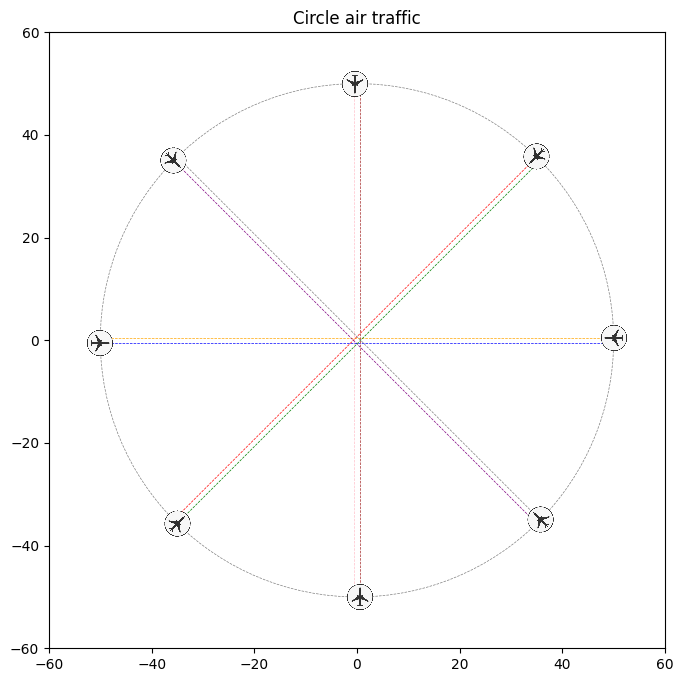

In [4]:
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.patches import Arc
from PIL import Image as PILImage
import numpy as np

plane_img = PILImage.open("plane.png").convert("RGBA")

def show_input(air_traffic, show_circle=False,show_arc_limits=False):
    _, axe = plt.subplots(figsize=(8, 8))
    # Show circle
    if show_circle:
        circle = plt.Circle(
            (0, 0),
            air_traffic.nominal_direction_length / 2,
            facecolor="none",
            edgecolor="grey",
            linestyle="--",
            linewidth=0.5,
        )
        axe.add_artist(circle)

    # Plot nominal directions
    for i in range(air_traffic.nb_of_aircraft):
        x0, y0 = air_traffic.aircraft[i].P
        theta = air_traffic.aircraft[i].Theta
        x1 = x0 + air_traffic.nominal_direction_length * cos(theta)
        y1 = y0 + air_traffic.nominal_direction_length * sin(theta)
        axe.plot(
            [x0, x1],
            [y0, y1],
            color=colors_list[i],
            linestyle="--",
            linewidth=0.5,
        )
        if show_arc_limits:
            arc_radius = air_traffic.nominal_direction_length / 6
            arc_center_x = x1 - arc_radius * cos(theta)
            arc_center_y = y1 - arc_radius * sin(theta)

            arc = Arc(
                (arc_center_x, arc_center_y),
                width=2 * arc_radius,
                height=2 * arc_radius,
                angle=degrees(theta),
                theta1=-10,
                theta2=10,
                color=colors_list[i],
                linewidth=0.5
            )
            axe.add_patch(arc)
        

    # Plot aircraft positions
    for i in range(air_traffic.nb_of_aircraft):
        x, y = air_traffic.aircraft[i].P
        angle_to_center = degrees(air_traffic.aircraft[i].Theta) - 90

        rotated_img = plane_img.rotate(
            angle_to_center, resample=PILImage.BICUBIC, expand=True
        )
        rotated_np = np.array(rotated_img)

        imagebox = OffsetImage(
            rotated_np,
            zoom=1.8 * air_traffic.D / (air_traffic.x_axis[1] - air_traffic.x_axis[0]),
        )
        ab = AnnotationBbox(imagebox, (x, y), frameon=False)
        axe.add_artist(ab)

    axe.set_xlim(air_traffic.x_axis)
    axe.set_ylim(air_traffic.y_axis)
    axe.set_aspect("equal", adjustable="box")
    axe.set_title(air_traffic.name)

show_input(air_traffic_0, show_circle=True)

## Model implementation

We implement the model using Pyomo, and solve it with Knitro.

In [5]:
import pyomo.environ as pyo


def create_model(air_traffic, objective="speed+angle"):
    model = pyo.ConcreteModel()

    ####################
    # Create variables #
    ####################

    model.Aircraft = pyo.RangeSet(0, air_traffic.nb_of_aircraft - 1)

    pair_ij = [
        (i, j)
        for i in range(air_traffic.nb_of_aircraft)
        for j in range(air_traffic.nb_of_aircraft)
        if i < j
    ]

    model.Pairs = pyo.RangeSet(0, len(pair_ij) - 1)

    # Magnitude of modified speed
    model.v = pyo.Var(model.Aircraft)

    # Modified heading angle
    def theta_bounds_rule(model, i):
        return (
            air_traffic.aircraft[i].Theta + air_traffic.aircraft[i].Omega_min,
            air_traffic.aircraft[i].Theta + air_traffic.aircraft[i].Omega_max,
        )

    model.theta = pyo.Var(model.Aircraft, bounds=theta_bounds_rule)

    # Scale factor applied to nominal speed
    def q_bounds_rule(model, i):
        return (air_traffic.aircraft[i].Q_min, air_traffic.aircraft[i].Q_max)

    model.q = pyo.Var(model.Aircraft, bounds=q_bounds_rule)

    # Variation of heading angle
    def omega_bounds_rule(model, i):
        return (air_traffic.aircraft[i].Omega_min, air_traffic.aircraft[i].Omega_max)

    model.omega = pyo.Var(model.Aircraft, bounds=omega_bounds_rule)

    # Sign of t_ij^min
    model.k = pyo.Var(model.Pairs, within=pyo.Binary)

    # Difference between modified vectors of velocity
    model.v_x = pyo.Var(model.Pairs)

    model.v_y = pyo.Var(model.Pairs)

    #############
    # Objective #
    #############

    # Minimize the sum of the deviations of the aircraft speeds and/or heading angles
    def objective_rule(model):
        if objective == "speed":
            return sum((model.q[i] - 1) ** 2 for i in model.Aircraft)
        if objective == "angle":
            return sum((model.omega[i]) ** 2 for i in model.Aircraft)
        else:  # "speed+angle"
            return sum(
                (model.q[i] - 1) ** 2 + (model.omega[i]) ** 2 for i in model.Aircraft
            )

    model.obj = pyo.Objective(rule=objective_rule, sense=pyo.minimize)

    ###############
    # Constraints #
    ###############

    # Definition of q
    def q_def_rule(model, i):
        return model.v[i] == model.q[i] * air_traffic.aircraft[i].V

    model.q_def = pyo.Constraint(model.Aircraft, rule=q_def_rule)

    # Definition of omega
    def omega_def_rule(model, i):
        return model.theta[i] == air_traffic.aircraft[i].Theta + model.omega[i]

    model.omega_def = pyo.Constraint(model.Aircraft, rule=omega_def_rule)

    # Definition of v_x
    def v_x_def_rule(model, ij):
        i, j = pair_ij[ij]
        return model.v_x[ij] == model.v[i] * pyo.cos(model.theta[i]) - model.v[
            j
        ] * pyo.cos(model.theta[j])

    model.v_x_def = pyo.Constraint(model.Pairs, rule=v_x_def_rule)

    # Definition of v_y
    def v_y_def_rule(model, ij):
        i, j = pair_ij[ij]
        return model.v_y[ij] == model.v[i] * pyo.sin(model.theta[i]) - model.v[
            j
        ] * pyo.sin(model.theta[j])

    model.v_y_def = pyo.Constraint(model.Pairs, rule=v_y_def_rule)

    # Sign of t_ij^min
    def time_sign_rule(model, ij):
        i, j = pair_ij[ij]
        return (
            (
                (air_traffic.aircraft[i].P[0] - air_traffic.aircraft[j].P[0])
                * model.v_x[ij]
                + (air_traffic.aircraft[i].P[1] - air_traffic.aircraft[j].P[1])
                * model.v_y[ij]
            ) * (2 * model.k[ij] - 1)
            <= 0
        )

    model.time_sign = pyo.Constraint(model.Pairs, rule=time_sign_rule)

    # Pairwise aircraft separation
    def aircraft_separation_rule(model, ij):
        i, j = pair_ij[ij]
        return (
            model.k[ij]
            * (
                (model.v_x[ij] ** 2 + model.v_y[ij] ** 2)
                * (
                    (air_traffic.aircraft[i].P[0] - air_traffic.aircraft[j].P[0]) ** 2
                    + (air_traffic.aircraft[i].P[1] - air_traffic.aircraft[j].P[1]) ** 2
                    - air_traffic.D**2
                )
                - (
                    (air_traffic.aircraft[i].P[0] - air_traffic.aircraft[j].P[0])
                    * model.v_x[ij]
                    + (air_traffic.aircraft[i].P[1] - air_traffic.aircraft[j].P[1])
                    * model.v_y[ij]
                )
                ** 2
            )
            >= 0
        )

    model.aircraft_separation = pyo.Constraint(
        model.Pairs, rule=aircraft_separation_rule
    )

    return model

In [6]:
model_0 = create_model(air_traffic_0)
solver = pyo.SolverFactory("knitroampl")
solver.options["mip_multistart"] = 1
solver.options["mip_maxnodes"] = 500

result = solver.solve(model_0, tee=True)

Artelys Knitro 15.0.0: mip_multistart=1
mip_maxnodes=500

          Commercial License
         Artelys Knitro 15.0.0

No start point provided -- Knitro computing one.

concurrent_evals         0
datacheck                0
feastol                  1e-06
feastol_abs              1e-06
findiff_numthreads       1
hessian_no_f             1
hessopt                  1
mip_maxnodes             500
mip_multistart           1
opttol                   1e-06
opttol_abs               0.001
Knitro changing mip_method from AUTO to 1.
Knitro changing mip_root_nlpalg from AUTO to 1.
Knitro changing mip_branchrule from AUTO to 2.
Knitro changing mip_selectrule from AUTO to 2.
Knitro changing mip_mir from AUTO to 2.
Knitro changing mip_clique from AUTO to 0.
Knitro changing mip_zerohalf from AUTO to 0.
Knitro changing mip_liftproject from AUTO to 0.
Knitro changing mip_knapsack from AUTO to 2.
Knitro changing mip_gomory from AUTO to 0.
Knitro changing mip_cut_flowcover from AUTO to 2.
Knitro changing m

## Output visualization

Let's visualize the solution found by the solver.

In [7]:
def print_results(air_traffic, model):
    print(f"{air_traffic.name}:")
    print()
    print("Solution:")
    print("-------------------")
    print(f"Objective: ${model.obj():,.3f}\n")
    for i in range(air_traffic.nb_of_aircraft):
        print(
            f"Aircraft {i}:   v_{i} = {model.v[i]():,.3f},  theta_{i} = {model.theta[i]():,.3f},  q_{i} = {model.q[i]():,.3f},  omega_{i} = {model.omega[i]():,.3f}"
        )
    print()

In [8]:
print_results(air_traffic_0, model_0)

Circle air traffic:

Solution:
-------------------
Objective: $0.105

Aircraft 0:   v_0 = 3.271,  theta_0 = 3.043,  q_0 = 0.981,  omega_0 = -0.098
Aircraft 1:   v_1 = 3.320,  theta_1 = 3.819,  q_1 = 0.996,  omega_1 = -0.108
Aircraft 2:   v_2 = 3.358,  theta_2 = 4.606,  q_2 = 1.007,  omega_2 = -0.107
Aircraft 3:   v_3 = 3.338,  theta_3 = 5.347,  q_3 = 1.002,  omega_3 = -0.151
Aircraft 4:   v_4 = 3.478,  theta_4 = 6.274,  q_4 = 1.043,  omega_4 = -0.009
Aircraft 5:   v_5 = 3.623,  theta_5 = 6.952,  q_5 = 1.087,  omega_5 = -0.117
Aircraft 6:   v_6 = 3.000,  theta_6 = 7.883,  q_6 = 0.900,  omega_6 = 0.029
Aircraft 7:   v_7 = 3.235,  theta_7 = 8.522,  q_7 = 0.970,  omega_7 = -0.118



In [9]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display, Image


def animate_air_traffic(air_traffic, model, show_circle=False, show_arc_limits=False):
    interval = 250  # time between frames in milliseconds
    fig, ax = plt.subplots(figsize=(8, 8))

    circle = plt.Circle(
        (0, 0),
        air_traffic.nominal_direction_length / 2,
        facecolor="none",
        edgecolor="grey",
        linestyle="--",
        linewidth=0.5,
    )

    def update(t):
        ax.clear()
        if show_circle:
            ax.add_artist(circle)

        # Plot nominal directions
        for i in range(air_traffic.nb_of_aircraft):
            x0, y0 = air_traffic.aircraft[i].P
            theta = air_traffic.aircraft[i].Theta
            x1 = x0 + air_traffic.nominal_direction_length * cos(theta)
            y1 = y0 + air_traffic.nominal_direction_length * sin(theta)
            ax.plot(
                [x0, x1],
                [y0, y1],
                color=colors_list[i],
                linestyle="--",
                linewidth=0.5,
            )
            if show_arc_limits:
                arc_radius = air_traffic.nominal_direction_length / 6
                arc_center_x = x1 - arc_radius * cos(theta)
                arc_center_y = y1 - arc_radius * sin(theta)

                arc = Arc(
                    (arc_center_x, arc_center_y),
                    width=2 * arc_radius,
                    height=2 * arc_radius,
                    angle=degrees(theta),
                    theta1=-10,
                    theta2=10,
                    color=colors_list[i],
                    linewidth=0.5
                )
                ax.add_patch(arc)

        # Plot effective directions
        for i in range(air_traffic.nb_of_aircraft):
            x, y = air_traffic.aircraft[i].P
            theta = model.theta[i]()
            ax.plot(
                [
                    x,
                    x
                    + air_traffic.nominal_direction_length
                    / air_traffic.aircraft[i].V
                    * model.v[i]()
                    * cos(theta),
                ],
                [
                    y,
                    y
                    + air_traffic.nominal_direction_length
                    / air_traffic.aircraft[i].V
                    * model.v[i]()
                    * sin(theta),
                ],
                color=colors_list[i],
                linewidth=0.5,
            )

        # Plot aircraft positions
        for i in range(air_traffic.nb_of_aircraft):
            # Compute position at time t
            x = air_traffic.aircraft[i].P[0] + model.v[i]() * cos(model.theta[i]()) * t
            y = air_traffic.aircraft[i].P[1] + model.v[i]() * sin(model.theta[i]()) * t
            angle = degrees(model.theta[i]()) - 90  # rotate image to match heading

            # Rotate plane image
            rotated_img = plane_img.rotate(angle, resample=PILImage.BICUBIC, expand=True)
            rotated_np = np.array(rotated_img)

            # Place image at aircraft position
            imagebox = OffsetImage(
                rotated_np,
                zoom=1.8
                * air_traffic.D
                / (air_traffic.x_axis[1] - air_traffic.x_axis[0]),
            )
            ab = AnnotationBbox(imagebox, (x, y), frameon=False)
            ax.add_artist(ab)

        # Set plot limits and formatting
        ax.set_xlim(air_traffic.x_axis)
        ax.set_ylim(air_traffic.y_axis)
        ax.set_aspect("equal", adjustable="box")
        ax.set_title(f"{air_traffic.name}:   t = {t}")

    # Create animation
    anim = FuncAnimation(
        fig,
        update,
        frames=int(air_traffic.nominal_direction_length / air_traffic.aircraft[0].V)
        + 1,
        interval=interval,
    )

    # Return the HTML object to be rendered in Jupyter
    return HTML(anim.to_jshtml())

In [10]:
def show_output_time_t(air_traffic, model, t, axe, show_circle=False, show_arc_limits=False):
    if show_circle:
        circle = plt.Circle(
            (0, 0),
            air_traffic.nominal_direction_length / 2,
            facecolor="none",
            edgecolor="grey",
            linestyle="--",
            linewidth=0.5,
        )
        axe.add_artist(circle)

    # Plot nominal way
    for i in range(air_traffic.nb_of_aircraft):
        x0, y0 = air_traffic.aircraft[i].P
        theta = air_traffic.aircraft[i].Theta
        x1 = x0 + air_traffic.nominal_direction_length * cos(theta)
        y1 = y0 + air_traffic.nominal_direction_length * sin(theta)
        axe.plot(
            [x0, x1],
            [y0, y1],
            color=colors_list[i],
            linestyle="--",
            linewidth=0.5,
        )
        if show_arc_limits:
            arc_radius = air_traffic.nominal_direction_length / 6
            arc_center_x = x1 - arc_radius * cos(theta)
            arc_center_y = y1 - arc_radius * sin(theta)

            arc = Arc(
                (arc_center_x, arc_center_y),
                width=2 * arc_radius,
                height=2 * arc_radius,
                angle=degrees(theta),
                theta1=-10,
                theta2=10,
                color=colors_list[i],
                linewidth=0.5
            )
            axe.add_patch(arc)

    # Plot effective way
    for i in range(air_traffic.nb_of_aircraft):
        x, y = air_traffic.aircraft[i].P
        theta = model.theta[i]()
        axe.plot(
            [
                x,
                x
                + air_traffic.nominal_direction_length
                / air_traffic.aircraft[0].V
                * model.v[i]()
                * cos(theta),
            ],
            [
                y,
                y
                + air_traffic.nominal_direction_length
                / air_traffic.aircraft[0].V
                * model.v[i]()
                * sin(theta),
            ],
            color=colors_list[i],
            linewidth=0.5,
        )

    # Plot aircraft positions
    for i in range(air_traffic.nb_of_aircraft):
        x, y = (
            air_traffic.aircraft[i].P[0] + model.v[i]() * pyo.cos(model.theta[i]()) * t,
            air_traffic.aircraft[i].P[1] + model.v[i]() * pyo.sin(model.theta[i]()) * t,
        )
        angle_to_center = degrees(model.theta[i]()) - 90

        rotated_img = plane_img.rotate(
            angle_to_center, resample=PILImage.BICUBIC, expand=True
        )
        rotated_np = np.array(rotated_img)

        imagebox = OffsetImage(
            rotated_np,
            zoom=1.25 * air_traffic.D / (air_traffic.x_axis[1] - air_traffic.x_axis[0]),
        )
        ab = AnnotationBbox(imagebox, (x, y), frameon=False)
        axe.add_artist(ab)

    axe.set_xlim(air_traffic.x_axis)
    axe.set_ylim(air_traffic.y_axis)
    axe.set_xticks([])
    axe.set_yticks([])
    axe.set_xlabel("")
    axe.set_ylabel("")
    axe.set_aspect("equal", adjustable="box")
    axe.set_title(f"t = {t}")


def show_output_timeline(air_traffic, model, show_time, show_circle=False,show_arc_limits=False):
    frame = len(show_time) * 2
    fig, axes = plt.subplots(frame // 6, 3, figsize=(18, frame))
    plt.subplots_adjust(wspace=0.1, hspace=0.1)
    fig.suptitle(f"{air_traffic.name}", y=0.91)

    for i in range(len(show_time)):
        show_output_time_t(
            air_traffic, model, show_time[i], axes[i // 3, i % 3], show_circle,show_arc_limits
        )

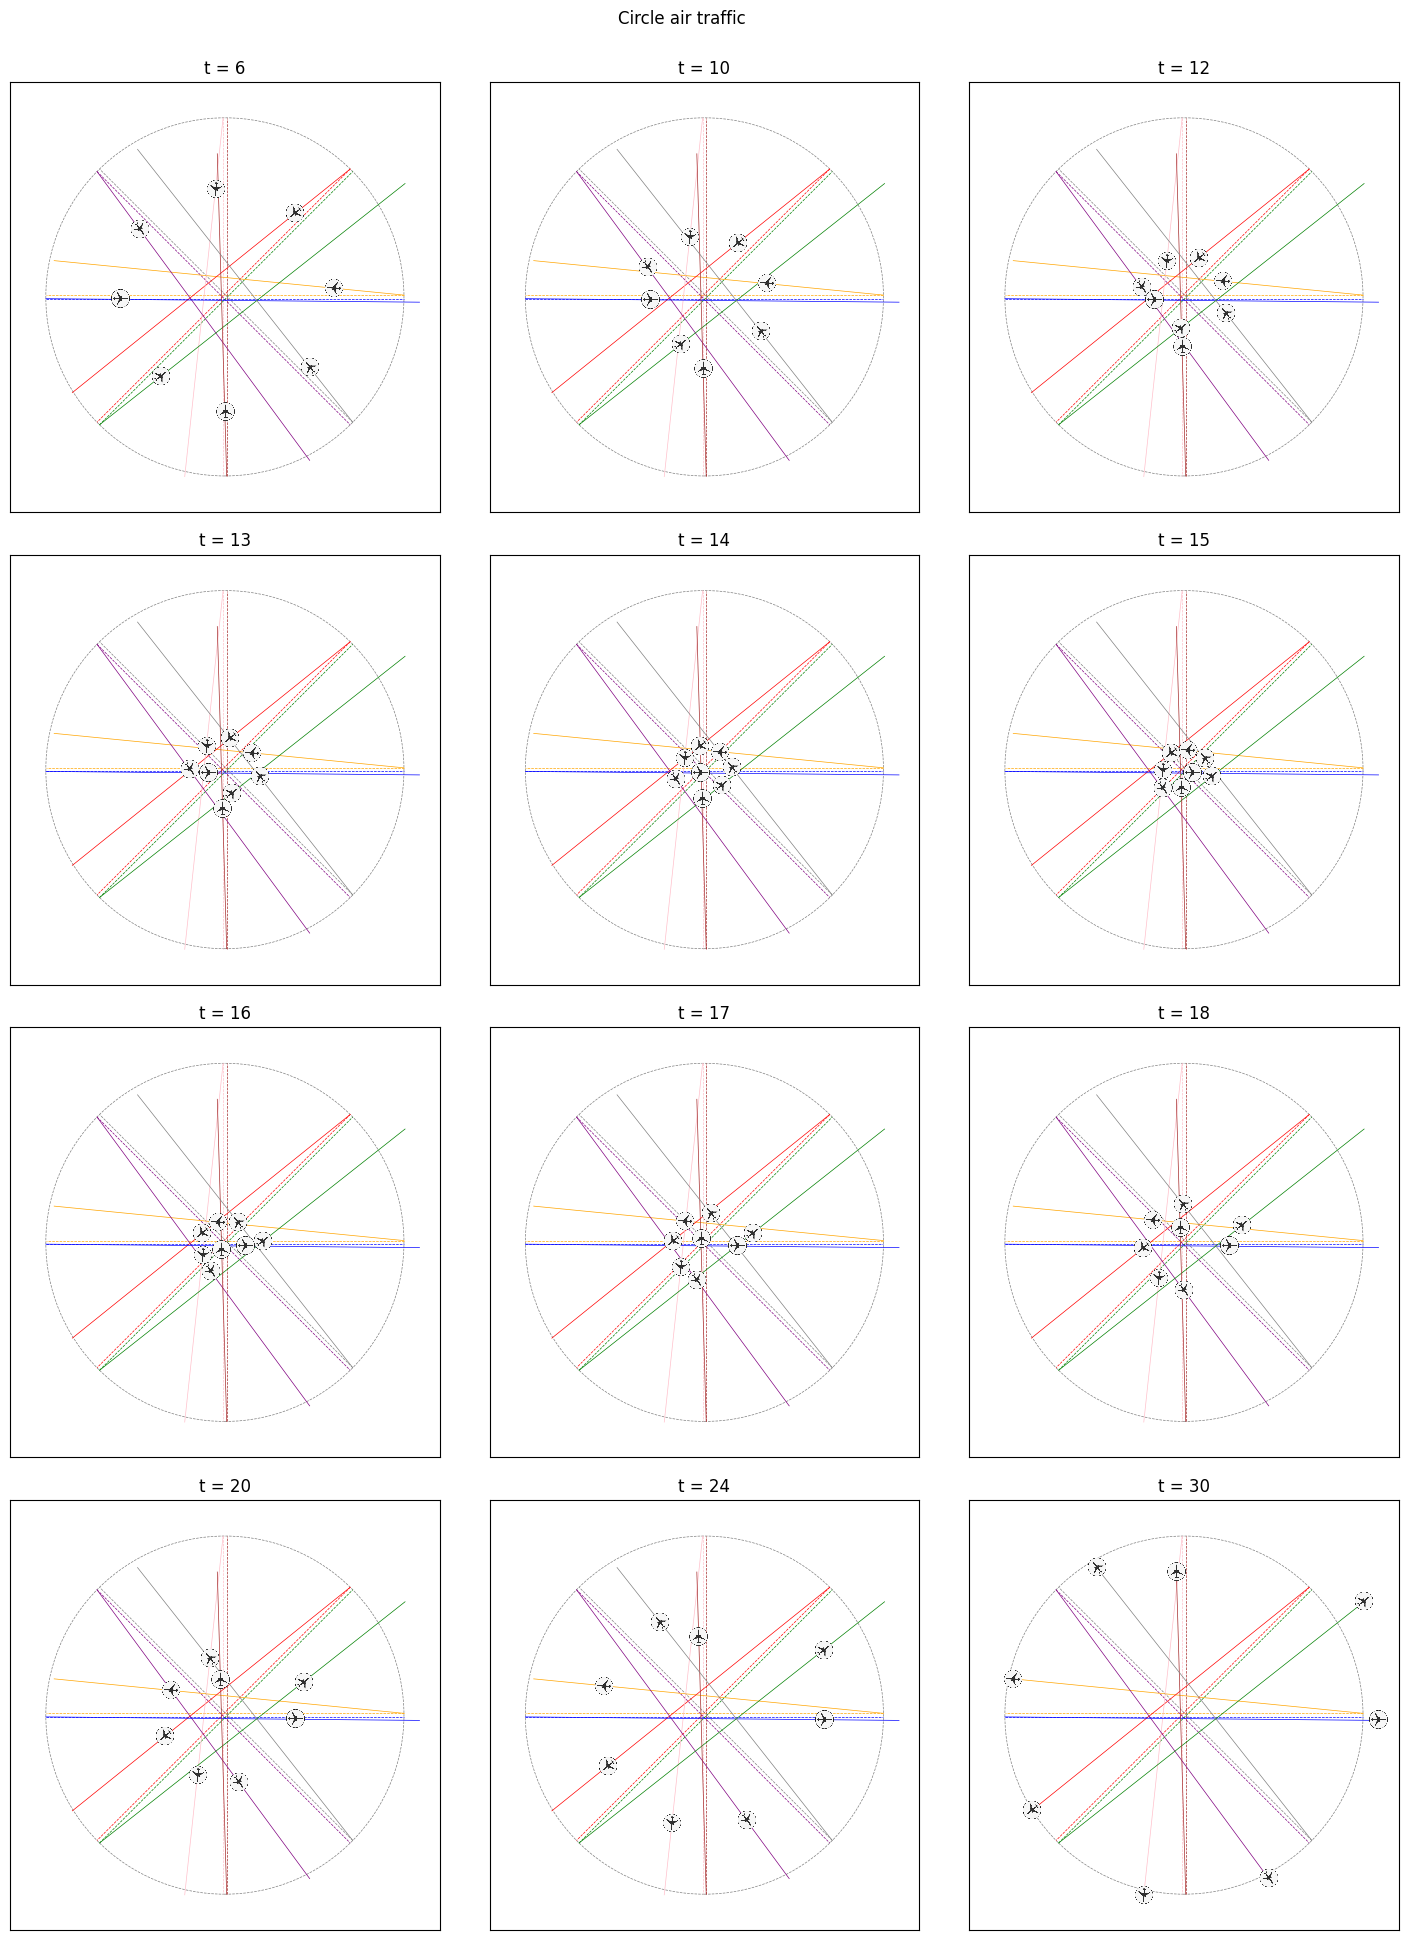

In [11]:
if anim:
    display(animate_air_traffic(air_traffic_0, model_0, show_circle=True))
else:

    show_time_0 = [6, 10, 12, 13, 14, 15, 16, 17, 18, 20, 24, 30]
    show_output_timeline(air_traffic_0, model_0, show_time_0, show_circle=True)

An intuitive solution would follow a "roundabout" pattern, whereby every aircraft deviates its course by the same angle. Knitro found that a better solution exists, which is not symmetric and rather counter-intuitive: This solution requires two airplanes to fly straight  through the center (one accelerates, the other decelerates), and the others to deviate from their original course following a roundabout pattern.

We can see the speed of the planes on the figures in addition to the angle: at the end of the simulation, a plane whose speed is not modified will have covered the same distance as nominal. For example, in this simulation, the planes that accelerated would have exceeded the limits of the circle, while those that decelerated remain inside the circle.

In all figures, the circles surrounding the aircraft have a diameter the size of the minimum miss distance between aircraft.

## Second use case: sector circle air traffic

This example is a variant of the first one, with 8 aircraft uniformly distributed on a quarter of the circumference of the circle, always converging to the center of the circle at the same speed.

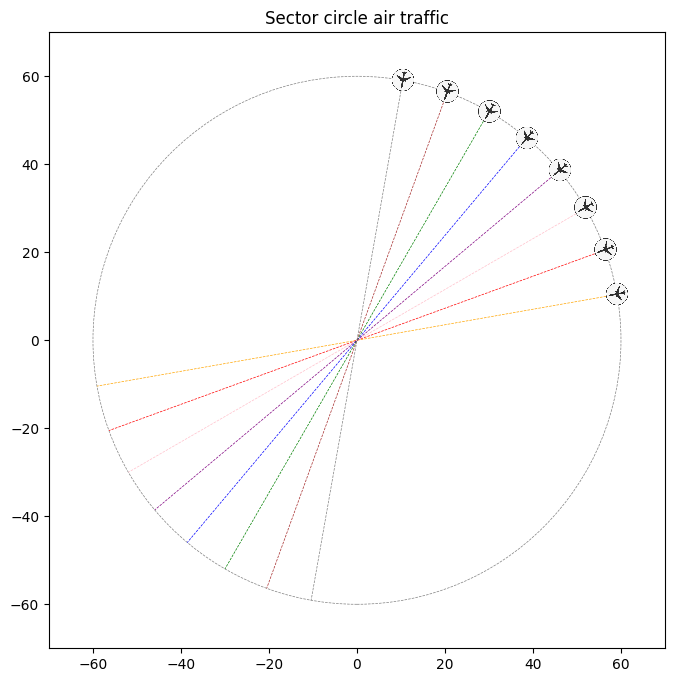

In [12]:
# Use case 1:   Sector circle air traffic
nb_of_aircraft_1 = 8
air_traffic_1 = AirTrafficInstance(nb_of_aircraft_1)
air_traffic_1.name = "Sector circle air traffic"
air_traffic_1.D = 5
air_traffic_1.nominal_direction_length = 120
air_traffic_1.x_axis = (-70, 70)
air_traffic_1.y_axis = (-70, 70)

# Init aircraft
for i in range(nb_of_aircraft_1):
    air_traffic_1.aircraft[i].P = (
        60 * cos(pi / 18 * (i + 1)),
        60 * sin(pi / 18 * (i + 1)),
    )
    air_traffic_1.aircraft[i].V = 10 / 3  # 200 knots
    air_traffic_1.aircraft[i].Theta = pi + pi / 18 * (i + 1)
    air_traffic_1.aircraft[i].Q_min = 0.9
    air_traffic_1.aircraft[i].Q_max = 1.1
    air_traffic_1.aircraft[i].Omega_min = -pi / 16
    air_traffic_1.aircraft[i].Omega_max = pi / 16

show_input(air_traffic_1, show_circle=True)
plt.show()

Let's solve it and visualize the solution.

In [13]:
model_1 = create_model(air_traffic_1)

result = solver.solve(model_1, tee=True)

Artelys Knitro 15.0.0: mip_multistart=1
mip_maxnodes=500

          Commercial License
         Artelys Knitro 15.0.0

No start point provided -- Knitro computing one.

concurrent_evals         0
datacheck                0
feastol                  1e-06
feastol_abs              1e-06
findiff_numthreads       1
hessian_no_f             1
hessopt                  1
mip_maxnodes             500
mip_multistart           1
opttol                   1e-06
opttol_abs               0.001
Knitro changing mip_method from AUTO to 1.
Knitro changing mip_root_nlpalg from AUTO to 1.
Knitro changing mip_branchrule from AUTO to 2.
Knitro changing mip_selectrule from AUTO to 2.
Knitro changing mip_mir from AUTO to 2.
Knitro changing mip_clique from AUTO to 0.
Knitro changing mip_zerohalf from AUTO to 0.
Knitro changing mip_liftproject from AUTO to 0.
Knitro changing mip_knapsack from AUTO to 2.
Knitro changing mip_gomory from AUTO to 0.
Knitro changing mip_cut_flowcover from AUTO to 2.
Knitro changing m

Sector circle air traffic:

Solution:
-------------------
Objective: $0.163

Aircraft 0:   v_0 = 3.637,  theta_0 = 3.511,  q_0 = 1.091,  omega_0 = 0.195
Aircraft 1:   v_1 = 3.000,  theta_1 = 3.534,  q_1 = 0.900,  omega_1 = 0.044
Aircraft 2:   v_2 = 3.000,  theta_2 = 3.534,  q_2 = 0.900,  omega_2 = -0.131
Aircraft 3:   v_3 = 3.316,  theta_3 = 3.771,  q_3 = 0.995,  omega_3 = -0.069
Aircraft 4:   v_4 = 3.109,  theta_4 = 3.863,  q_4 = 0.933,  omega_4 = -0.152
Aircraft 5:   v_5 = 3.667,  theta_5 = 4.213,  q_5 = 1.100,  omega_5 = 0.024
Aircraft 6:   v_6 = 3.491,  theta_6 = 4.299,  q_6 = 1.047,  omega_6 = -0.064
Aircraft 7:   v_7 = 3.322,  theta_7 = 4.369,  q_7 = 0.997,  omega_7 = -0.169



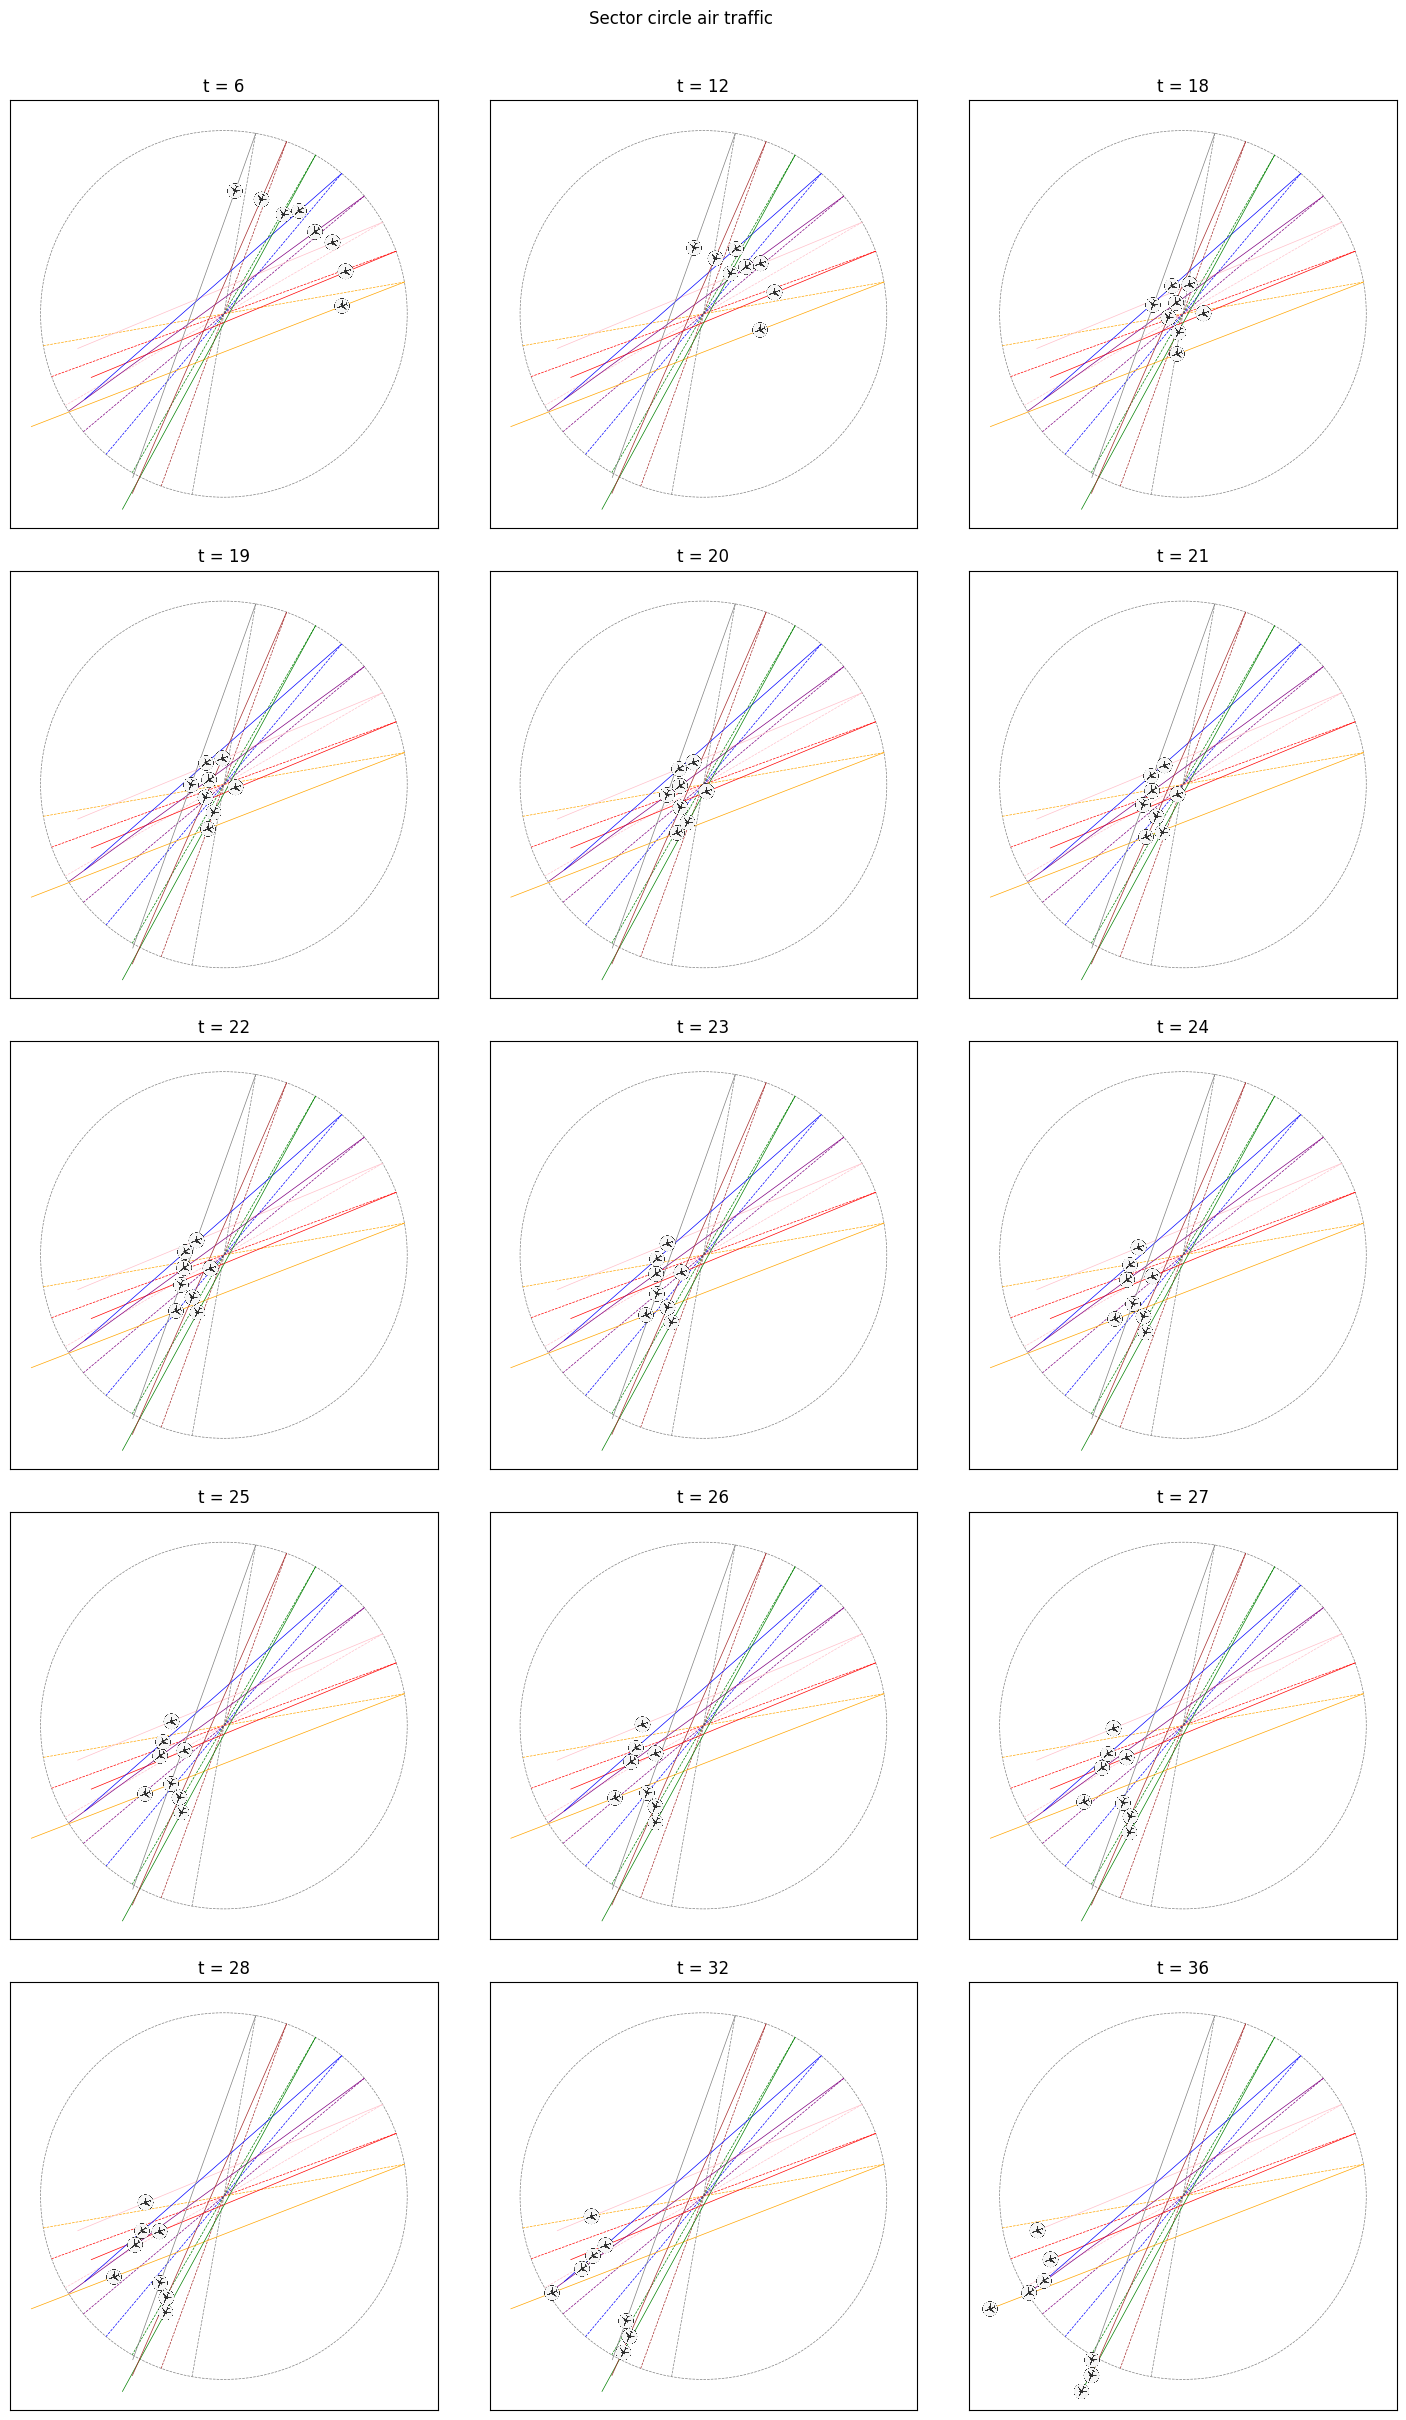

In [14]:
print_results(air_traffic_1, model_1)

if anim:
    display(animate_air_traffic(air_traffic_1, model_1, show_circle=True))
else:
    show_time_1 = [6, 12, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 32, 36]
    show_output_timeline(air_traffic_1, model_1, show_time_1, show_circle=True)

We can see that in this example, changing the angles is not enough, and some planes accelerate a lot while others slow down significantly.

## Third use case: two converging lines of four aircraft

In the third example, two strings of four aircraft spaced 25 miles-in-trail are converging towards each other at the same speed. 
The minimum miss distance was chosen arbitrarily to be 20 Nm. As a result, it is impossible to resolve conflicts arising between these two aircraft streams by using staging without path deviations: The distance between two consecutive aircraft in one stream does not allow the controller to insert an aircraft from the other stream between them without creating a conflict.

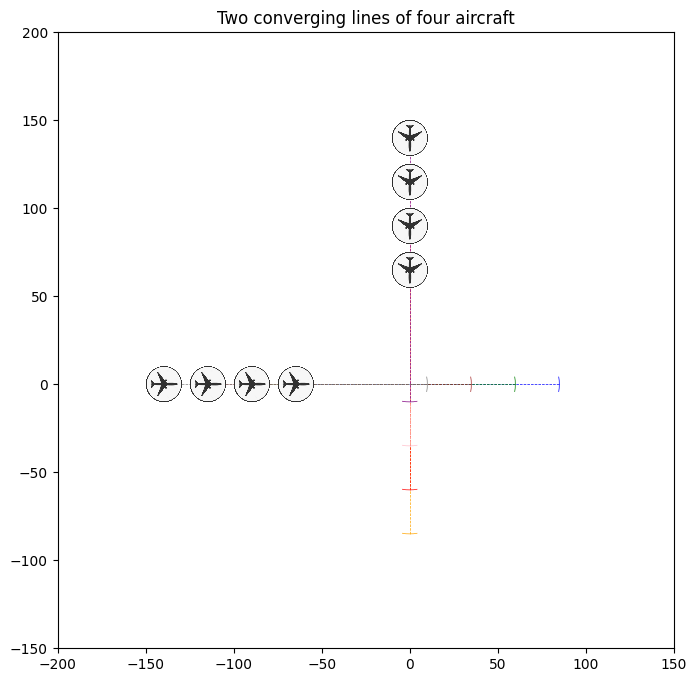

In [15]:
# Use case 2:   Two converging lines of four aircraft
nb_of_aircraft_2 = 8
air_traffic_2 = AirTrafficInstance(nb_of_aircraft_2)
air_traffic_2.name = "Two converging lines of four aircraft"
air_traffic_2.D = 20
air_traffic_2.nominal_direction_length = 150
air_traffic_2.x_axis = (-200, 150)
air_traffic_2.y_axis = (-150, 200)

# Init aircraft
for i in range(nb_of_aircraft_2):
    air_traffic_2.aircraft[i].P = (
        (0, 65 + 25 * i) if i in [0, 1, 2, 3] else (-65 - 25 * (i - 4), 0)
    )
    air_traffic_2.aircraft[i].V = 10 / 3  # 200 knots
    air_traffic_2.aircraft[i].Theta = 3 * pi / 2 if i in [0, 1, 2, 3] else 0
    air_traffic_2.aircraft[i].Q_min = 0.9
    air_traffic_2.aircraft[i].Q_max = 1.1
    air_traffic_2.aircraft[i].Omega_min = -pi / 16
    air_traffic_2.aircraft[i].Omega_max = pi / 16


show_input(air_traffic_2,show_arc_limits=True)
plt.show()

In [16]:
model_2 = create_model(air_traffic_2)

result = solver.solve(model_2, tee=True)

Artelys Knitro 15.0.0: mip_multistart=1
mip_maxnodes=500

          Commercial License
         Artelys Knitro 15.0.0

No start point provided -- Knitro computing one.

concurrent_evals         0
datacheck                0
feastol                  1e-06
feastol_abs              1e-06
findiff_numthreads       1
hessian_no_f             1
hessopt                  1
mip_maxnodes             500
mip_multistart           1
opttol                   1e-06
opttol_abs               0.001
Knitro changing mip_method from AUTO to 1.
Knitro changing mip_root_nlpalg from AUTO to 1.
Knitro changing mip_branchrule from AUTO to 2.
Knitro changing mip_selectrule from AUTO to 2.
Knitro changing mip_mir from AUTO to 2.
Knitro changing mip_clique from AUTO to 0.
Knitro changing mip_zerohalf from AUTO to 0.
Knitro changing mip_liftproject from AUTO to 0.
Knitro changing mip_knapsack from AUTO to 2.
Knitro changing mip_gomory from AUTO to 0.
Knitro changing mip_cut_flowcover from AUTO to 2.
Knitro changing m

Two converging lines of four aircraft:

Solution:
-------------------
Objective: $0.127

Aircraft 0:   v_0 = 3.667,  theta_0 = 4.909,  q_0 = 1.100,  omega_0 = 0.196
Aircraft 1:   v_1 = 3.078,  theta_1 = 4.636,  q_1 = 0.923,  omega_1 = -0.076
Aircraft 2:   v_2 = 3.377,  theta_2 = 4.763,  q_2 = 1.013,  omega_2 = 0.051
Aircraft 3:   v_3 = 3.000,  theta_3 = 4.599,  q_3 = 0.900,  omega_3 = -0.113
Aircraft 4:   v_4 = 3.051,  theta_4 = 0.026,  q_4 = 0.915,  omega_4 = 0.026
Aircraft 5:   v_5 = 3.447,  theta_5 = -0.121,  q_5 = 1.034,  omega_5 = -0.121
Aircraft 6:   v_6 = 3.067,  theta_6 = 0.105,  q_6 = 0.920,  omega_6 = 0.105
Aircraft 7:   v_7 = 3.307,  theta_7 = -0.006,  q_7 = 0.992,  omega_7 = -0.006



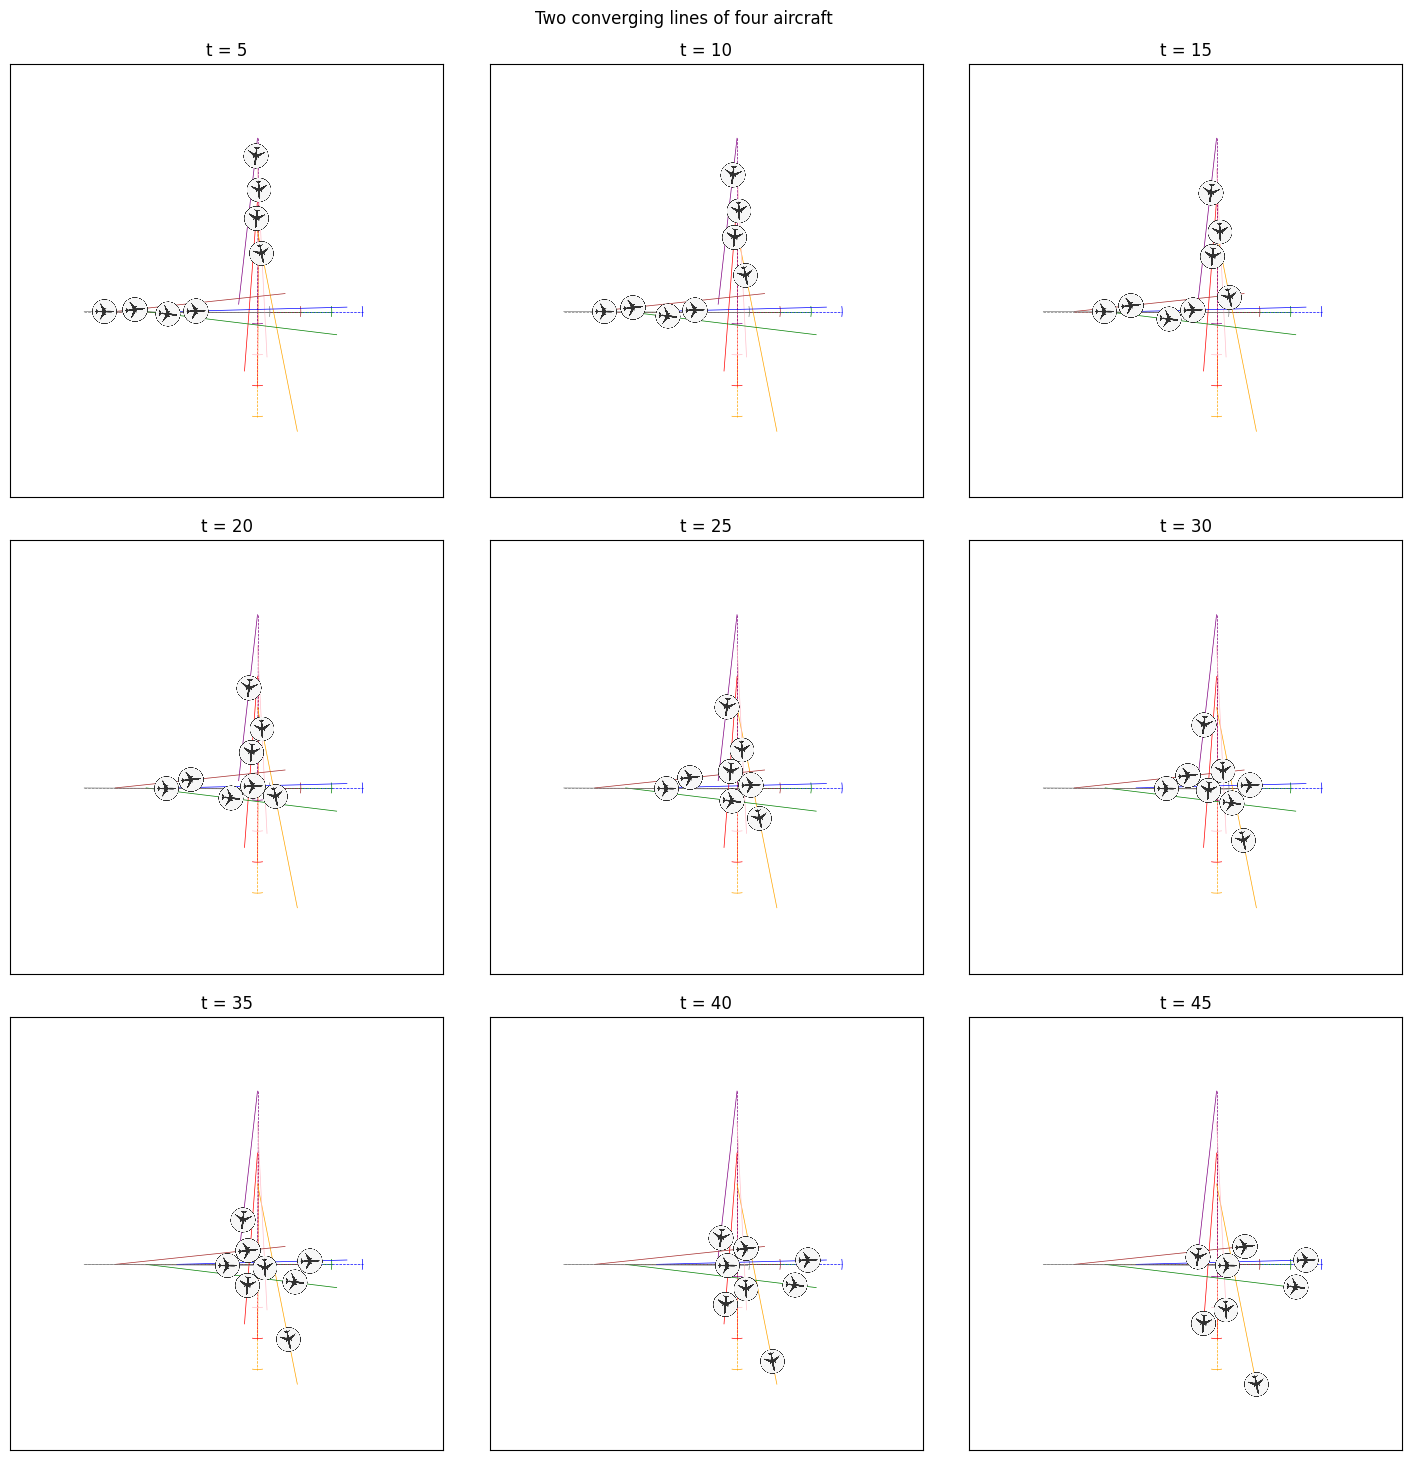

In [17]:
print_results(air_traffic_2, model_2)

if anim:
    display(animate_air_traffic(air_traffic_2, model_2,show_arc_limits=True))
else:
    show_time_2 = [5, 10, 15, 20, 25, 30, 35, 40, 45]
    show_output_timeline(air_traffic_2, model_2, show_time_2,show_arc_limits=True)

## Fourth use case: ten random aircraft

In this example, a set of 10 aircraft flying at a nominal speed of 200 knots was positioned and oriented at random. This initial configuration generates conflicts among those aircraft which have to be avoided.

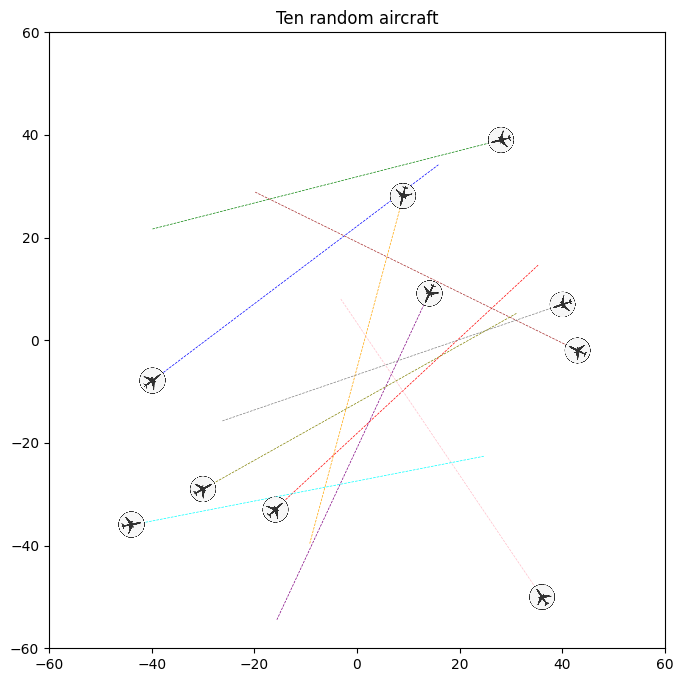

In [18]:
# Use case 3:   Ten random aircraft
import random

random.seed(9)

nb_of_aircraft_3 = 10
air_traffic_3 = AirTrafficInstance(nb_of_aircraft_3)
air_traffic_3.name = "Ten random aircraft"
air_traffic_3.D = 5
air_traffic_3.nominal_direction_length = 70
air_traffic_3.x_axis = (-60, 60)
air_traffic_3.y_axis = (-60, 60)

# Init aircraft
for i in range(nb_of_aircraft_3):
    air_traffic_3.aircraft[i].P = random.randint(-50, 50), random.randint(-50, 50)
    air_traffic_3.aircraft[i].V = 10 / 3  # 200 knots
    air_traffic_3.aircraft[i].Theta = (
        atan(air_traffic_3.aircraft[i].P[1] / air_traffic_3.aircraft[i].P[0])
        + random.randint(-180, 180) / 180 * pi / 4
    )  # it could not works if air_traffic_3.aircraft[i].P[0]==0
    if air_traffic_3.aircraft[i].P[0] > 0:
        air_traffic_3.aircraft[i].Theta += pi
    air_traffic_3.aircraft[i].Q_min = 0.9
    air_traffic_3.aircraft[i].Q_max = 1.1
    air_traffic_3.aircraft[i].Omega_min = -pi / 16
    air_traffic_3.aircraft[i].Omega_max = pi / 16

show_input(air_traffic_3)
plt.show()

In [19]:
model_3 = create_model(air_traffic_3)
result = solver.solve(model_3, tee=True)

Artelys Knitro 15.0.0: mip_multistart=1
mip_maxnodes=500

          Commercial License
         Artelys Knitro 15.0.0

No start point provided -- Knitro computing one.

concurrent_evals         0
datacheck                0
feastol                  1e-06
feastol_abs              1e-06
findiff_numthreads       1
hessian_no_f             1
hessopt                  1
mip_maxnodes             500
mip_multistart           1
opttol                   1e-06
opttol_abs               0.001
Knitro changing mip_method from AUTO to 1.
Knitro changing mip_root_nlpalg from AUTO to 1.
Knitro changing mip_branchrule from AUTO to 2.
Knitro changing mip_selectrule from AUTO to 2.
Knitro changing mip_mir from AUTO to 2.
Knitro changing mip_clique from AUTO to 0.
Knitro changing mip_zerohalf from AUTO to 0.
Knitro changing mip_liftproject from AUTO to 0.
Knitro changing mip_knapsack from AUTO to 2.
Knitro changing mip_gomory from AUTO to 0.
Knitro changing mip_cut_flowcover from AUTO to 2.
Knitro changing m

Ten random aircraft:

Solution:
-------------------
Objective: $0.030

Aircraft 0:   v_0 = 3.279,  theta_0 = 4.406,  q_0 = 0.984,  omega_0 = -0.043
Aircraft 1:   v_1 = 3.399,  theta_1 = 0.650,  q_1 = 1.020,  omega_1 = -0.098
Aircraft 2:   v_2 = 3.333,  theta_2 = 2.164,  q_2 = 1.000,  omega_2 = -0.000
Aircraft 3:   v_3 = 3.249,  theta_3 = 4.208,  q_3 = 0.975,  omega_3 = -0.068
Aircraft 4:   v_4 = 3.369,  theta_4 = 0.665,  q_4 = 1.011,  omega_4 = 0.018
Aircraft 5:   v_5 = 3.333,  theta_5 = 3.392,  q_5 = 1.000,  omega_5 = -0.000
Aircraft 6:   v_6 = 3.103,  theta_6 = 2.690,  q_6 = 0.931,  omega_6 = 0.005
Aircraft 7:   v_7 = 3.504,  theta_7 = 3.435,  q_7 = 1.051,  omega_7 = -0.037
Aircraft 8:   v_8 = 3.319,  theta_8 = 0.537,  q_8 = 0.996,  omega_8 = 0.026
Aircraft 9:   v_9 = 3.413,  theta_9 = 0.142,  q_9 = 1.024,  omega_9 = -0.051



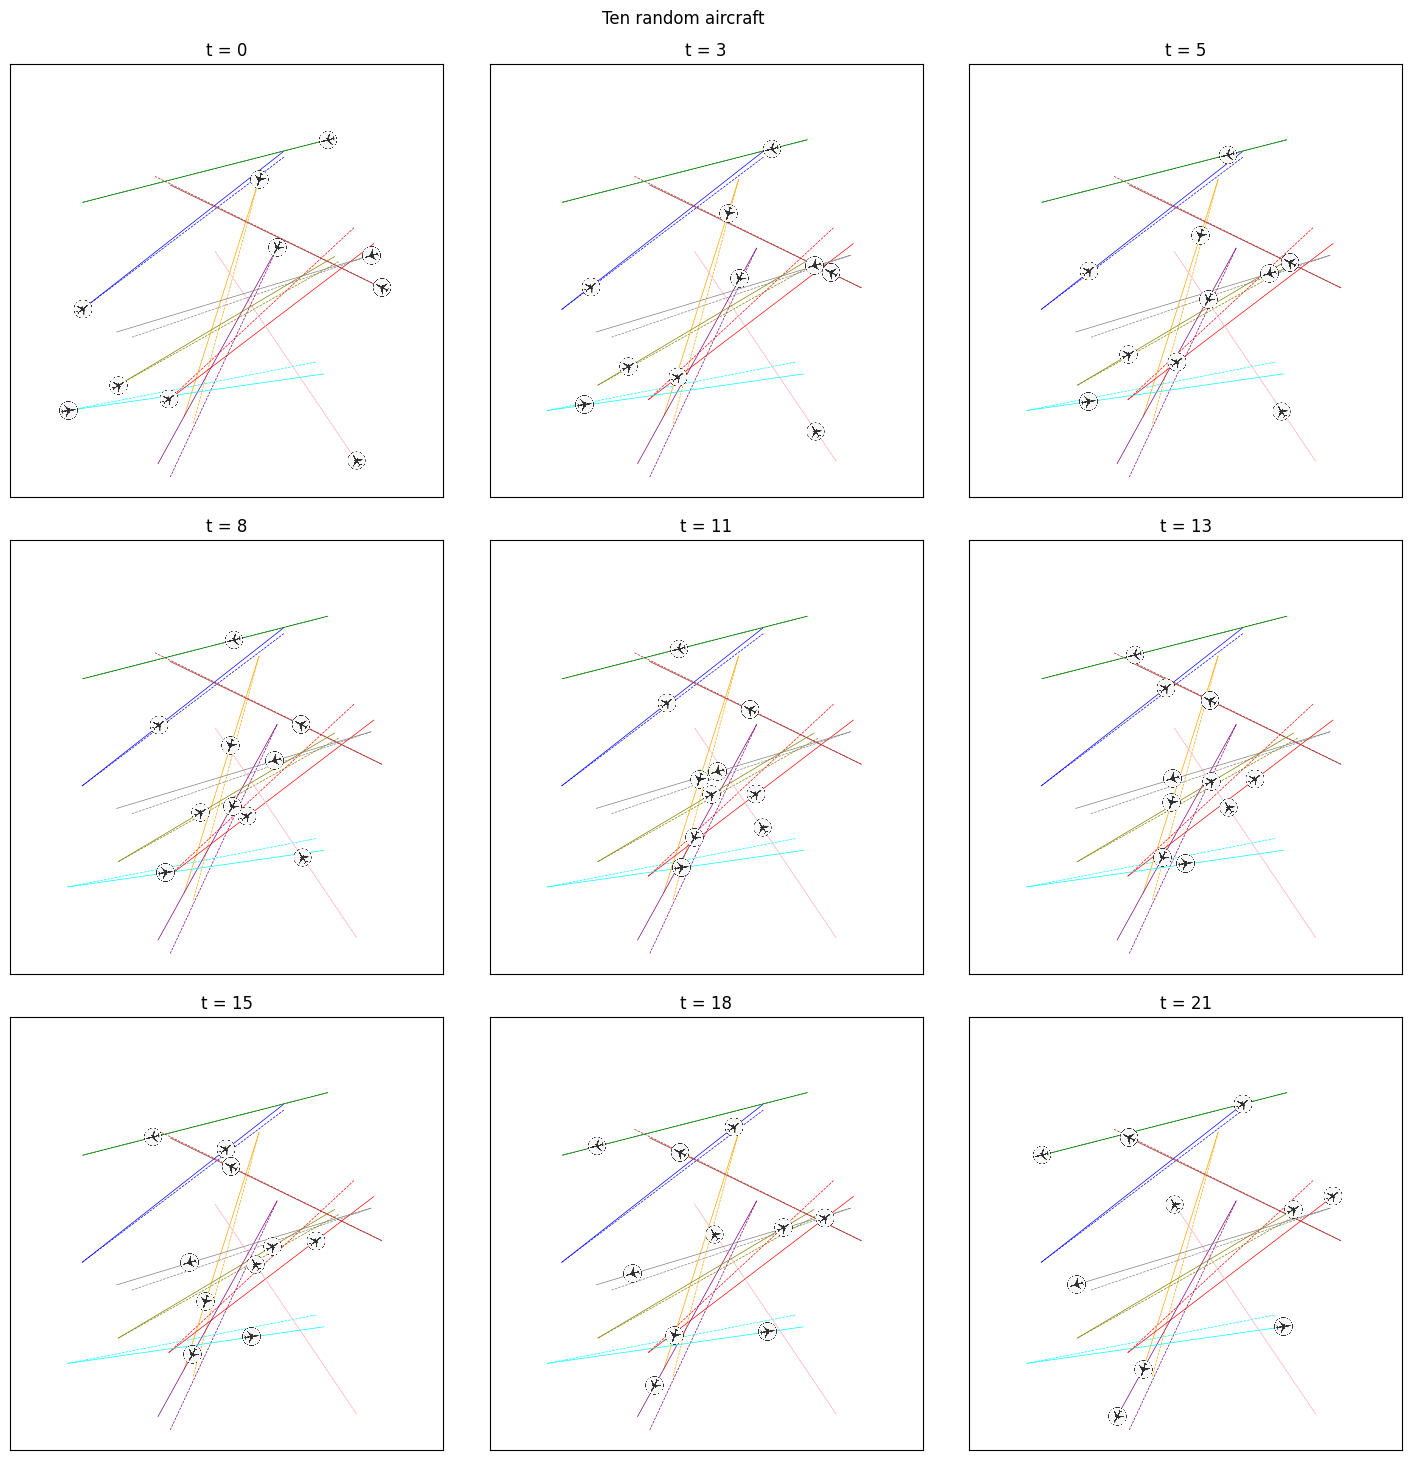

In [20]:
print_results(air_traffic_3, model_3)

if anim:
    display(animate_air_traffic(air_traffic_3, model_3))
else:
    show_time_3 = [0, 3, 5, 8, 11, 13, 15, 18, 21]
    show_output_timeline(air_traffic_3, model_3, show_time_3)

We can see that the 3 aircraft that did not conflict with the other aircraft did not change speed or direction. Their trajectories are therefore the same as the nominal ones.

## Model extensions

The goal of this section is to show how the solutions change when we change the objective function.

### Objective only taking into account the changes in speed

The new objective function is to minimize the sum of the differences in aircraft speeds (rather than the heading angles).

$$\min \sum_{i \in A} (q_i-1)^2$$

The heading angles can be adjusted, they are simply not considered in the objective function.

In [21]:
model_0_bis = create_model(air_traffic_0, "speed")
result = solver.solve(model_0_bis, tee=True)

Artelys Knitro 15.0.0: mip_multistart=1
mip_maxnodes=500

          Commercial License
         Artelys Knitro 15.0.0

No start point provided -- Knitro computing one.

concurrent_evals         0
datacheck                0
feastol                  1e-06
feastol_abs              1e-06
findiff_numthreads       1
hessian_no_f             1
hessopt                  1
mip_maxnodes             500
mip_multistart           1
opttol                   1e-06
opttol_abs               0.001
Knitro changing mip_method from AUTO to 1.
Knitro changing mip_root_nlpalg from AUTO to 1.
Knitro changing mip_branchrule from AUTO to 2.
Knitro changing mip_selectrule from AUTO to 2.
Knitro changing mip_mir from AUTO to 2.
Knitro changing mip_clique from AUTO to 0.
Knitro changing mip_zerohalf from AUTO to 0.
Knitro changing mip_liftproject from AUTO to 0.
Knitro changing mip_knapsack from AUTO to 2.
Knitro changing mip_gomory from AUTO to 0.
Knitro changing mip_cut_flowcover from AUTO to 2.
Knitro changing m

Circle air traffic:

Solution:
-------------------
Objective: $0.000

Aircraft 0:   v_0 = 3.333,  theta_0 = 2.979,  q_0 = 1.000,  omega_0 = -0.163
Aircraft 1:   v_1 = 3.333,  theta_1 = 3.768,  q_1 = 1.000,  omega_1 = -0.159
Aircraft 2:   v_2 = 3.333,  theta_2 = 4.565,  q_2 = 1.000,  omega_2 = -0.147
Aircraft 3:   v_3 = 3.333,  theta_3 = 5.337,  q_3 = 1.000,  omega_3 = -0.161
Aircraft 4:   v_4 = 3.333,  theta_4 = 6.123,  q_4 = 1.000,  omega_4 = -0.160
Aircraft 5:   v_5 = 3.333,  theta_5 = 6.916,  q_5 = 1.000,  omega_5 = -0.153
Aircraft 6:   v_6 = 3.333,  theta_6 = 7.705,  q_6 = 1.000,  omega_6 = -0.149
Aircraft 7:   v_7 = 3.333,  theta_7 = 8.465,  q_7 = 1.000,  omega_7 = -0.174



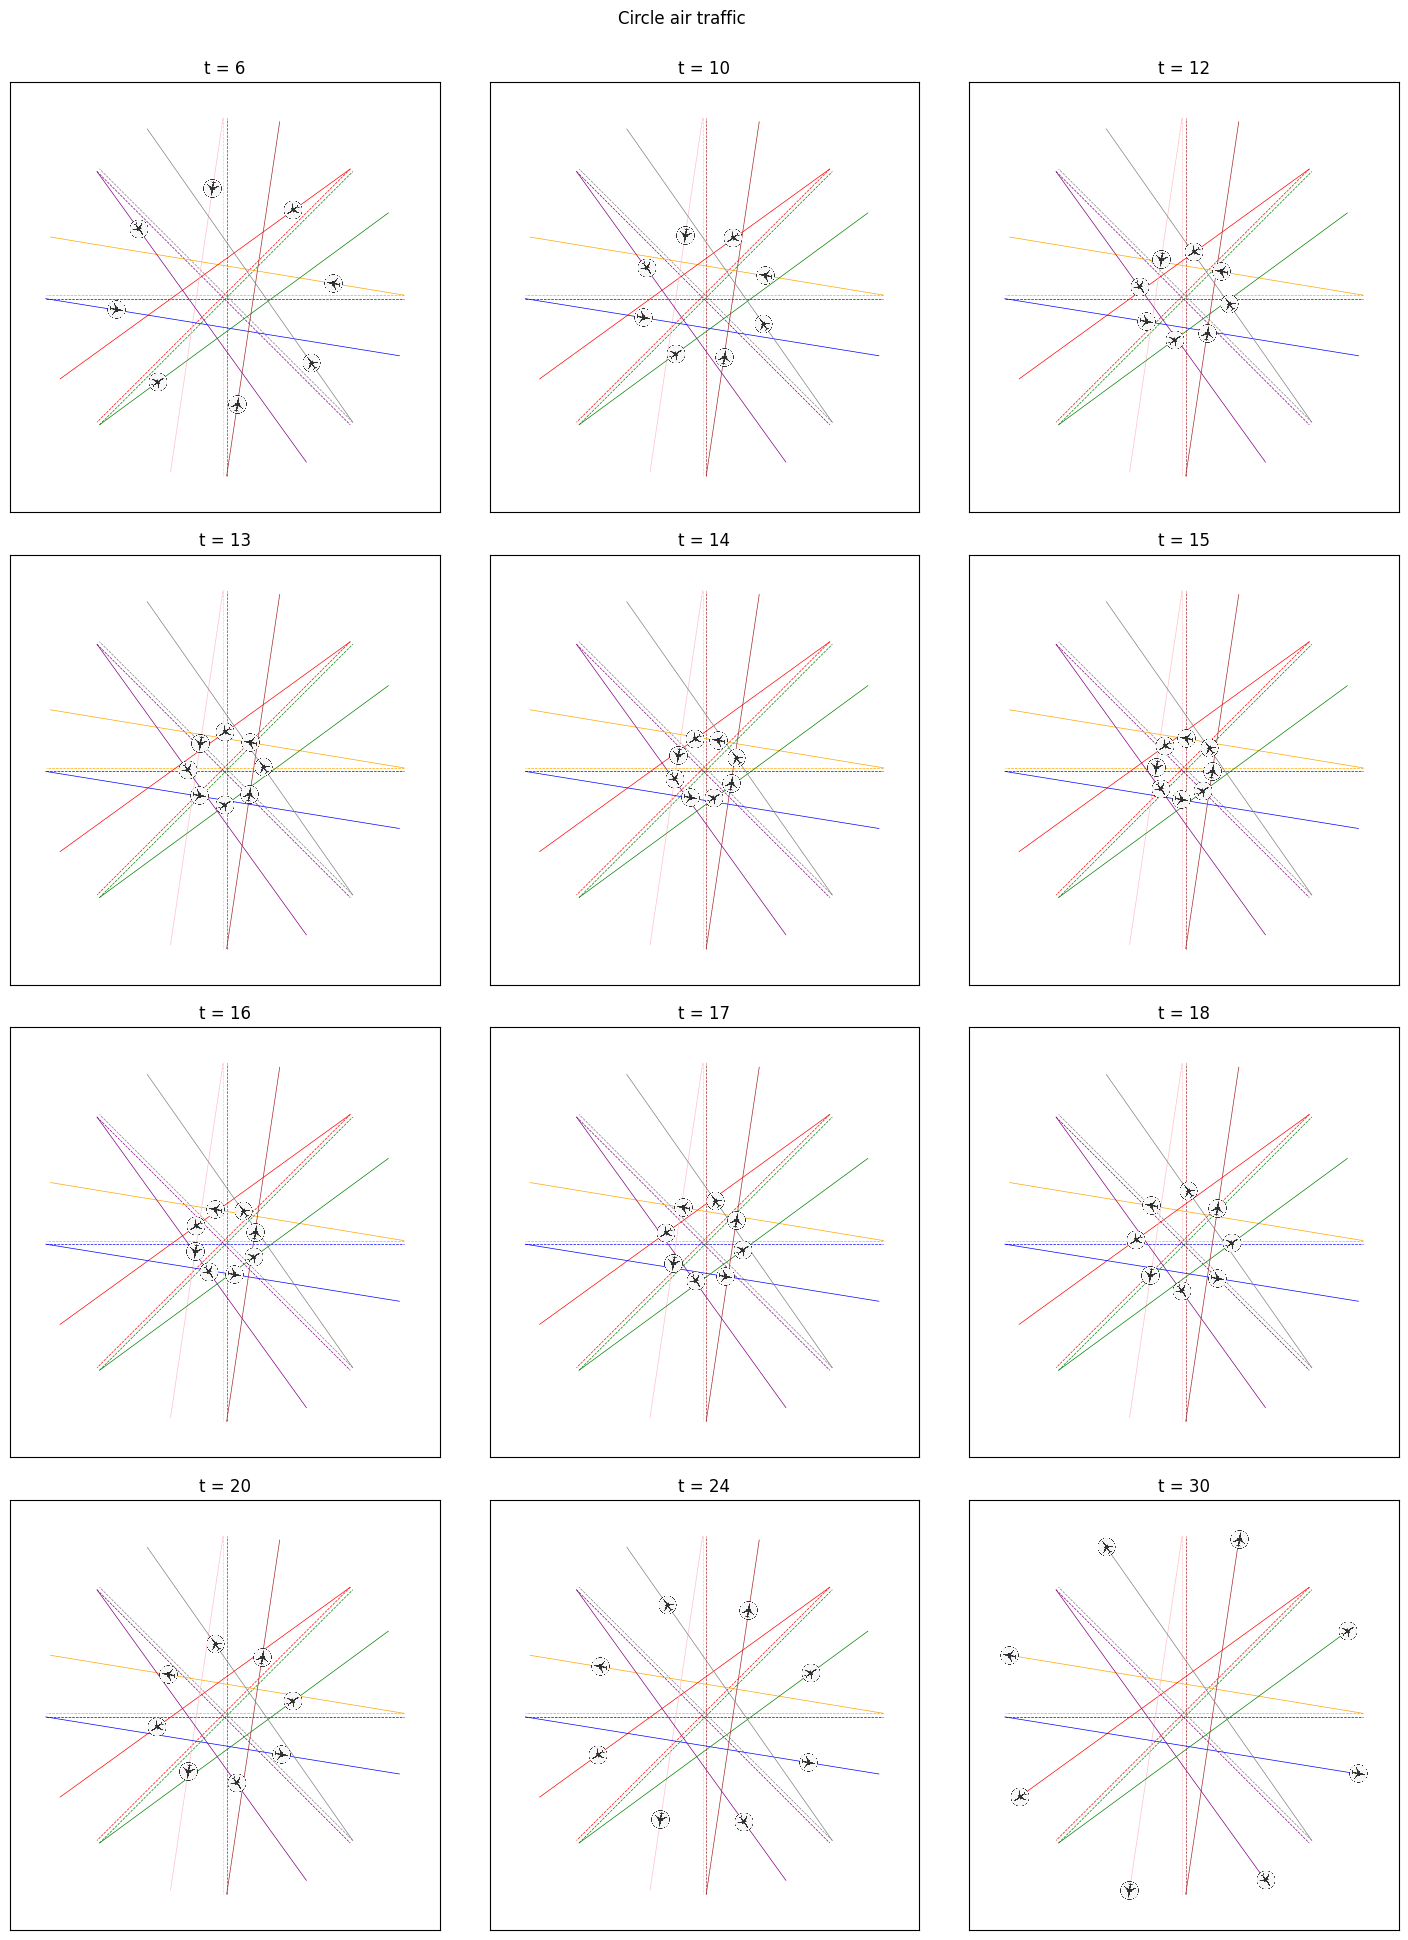

In [22]:
print_results(air_traffic_0, model_0_bis)

if anim:
    display(animate_air_traffic(air_traffic_0, model_0_bis))
else:
    show_output_timeline(air_traffic_0, model_0_bis, show_time_0)

### Objective only taking into account the changes in heading angle

The new objective function is to minimize the sum of the differences in aircraft heading angles (rather than the speeds).

$$\min \sum_{i \in A} \omega _i ^ 2 $$

The speeds can be adjusted, they are simply not considered in the objective function.

In [23]:
model_0_ter = create_model(air_traffic_0, "angle")
result = solver.solve(model_0_ter, tee=True)

Artelys Knitro 15.0.0: mip_multistart=1
mip_maxnodes=500

          Commercial License
         Artelys Knitro 15.0.0

No start point provided -- Knitro computing one.

concurrent_evals         0
datacheck                0
feastol                  1e-06
feastol_abs              1e-06
findiff_numthreads       1
hessian_no_f             1
hessopt                  1
mip_maxnodes             500
mip_multistart           1
opttol                   1e-06
opttol_abs               0.001
Knitro changing mip_method from AUTO to 1.
Knitro changing mip_root_nlpalg from AUTO to 1.
Knitro changing mip_branchrule from AUTO to 2.
Knitro changing mip_selectrule from AUTO to 2.
Knitro changing mip_mir from AUTO to 2.
Knitro changing mip_clique from AUTO to 0.
Knitro changing mip_zerohalf from AUTO to 0.
Knitro changing mip_liftproject from AUTO to 0.
Knitro changing mip_knapsack from AUTO to 2.
Knitro changing mip_gomory from AUTO to 0.
Knitro changing mip_cut_flowcover from AUTO to 2.
Knitro changing m

Circle air traffic:

Solution:
-------------------
Objective: $0.084

Aircraft 0:   v_0 = 3.365,  theta_0 = 3.046,  q_0 = 1.010,  omega_0 = -0.095
Aircraft 1:   v_1 = 3.360,  theta_1 = 3.776,  q_1 = 1.008,  omega_1 = -0.151
Aircraft 2:   v_2 = 3.593,  theta_2 = 4.726,  q_2 = 1.078,  omega_2 = 0.014
Aircraft 3:   v_3 = 3.211,  theta_3 = 5.488,  q_3 = 0.963,  omega_3 = -0.010
Aircraft 4:   v_4 = 3.667,  theta_4 = 6.171,  q_4 = 1.100,  omega_4 = -0.112
Aircraft 5:   v_5 = 3.667,  theta_5 = 6.939,  q_5 = 1.100,  omega_5 = -0.130
Aircraft 6:   v_6 = 3.000,  theta_6 = 7.969,  q_6 = 0.900,  omega_6 = 0.115
Aircraft 7:   v_7 = 3.294,  theta_7 = 8.544,  q_7 = 0.988,  omega_7 = -0.095



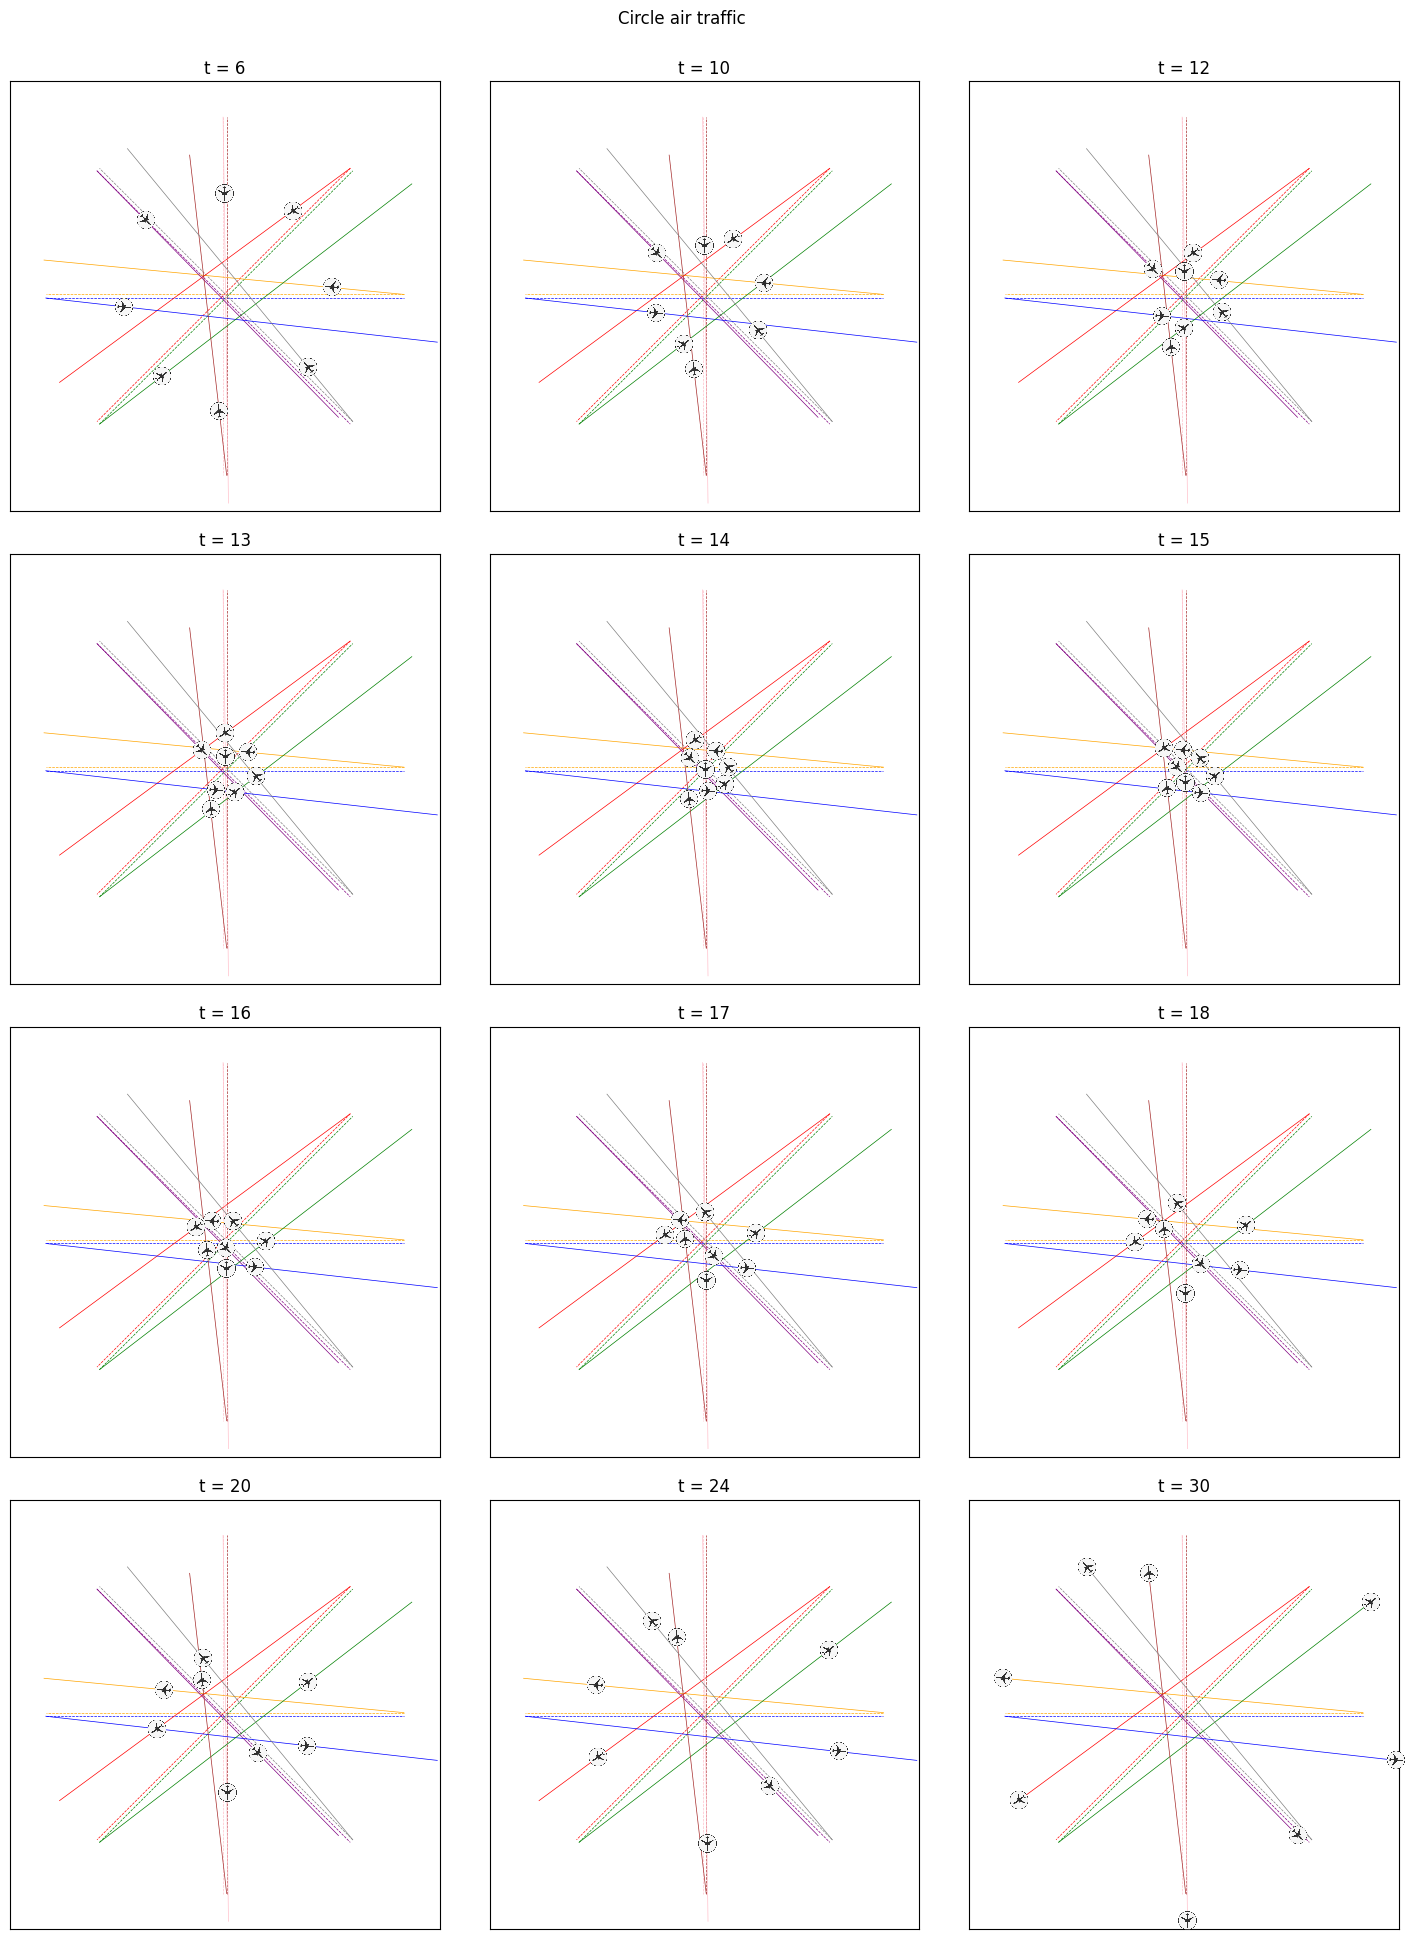

In [24]:
print_results(air_traffic_0, model_0_ter)

if anim:
    display(animate_air_traffic(air_traffic_0, model_0_ter))
else:
    show_output_timeline(air_traffic_0, model_0_ter, show_time_0)

We can now compare the solutions obtained with the new objectives to the previous ones.

In [25]:
def animate_air_traffic_comparison(air_traffic, models):
    interval = 250  # time between frames in milliseconds
    fig, axes = plt.subplots(figsize=(16, 6), ncols=3)
    fig.subplots_adjust(left=0.04, right=0.98, top=0.95, bottom=0.03, wspace=0.15)
    model_type = ["speed+angle", "speed", "angle"]

    def update(t):
        for j in range(3):
            model = models[j]
            ax = axes[j]
            ax.clear()

            # Plot nominal directions
            for i in range(air_traffic.nb_of_aircraft):
                x, y = air_traffic.aircraft[i].P
                theta = air_traffic.aircraft[i].Theta
                ax.plot(
                    [x, x + air_traffic.nominal_direction_length * cos(theta)],
                    [y, y + air_traffic.nominal_direction_length * sin(theta)],
                    color=colors_list[i],
                    linestyle="--",
                    linewidth=0.5,
                )

            # Plot effective directions
            for i in range(air_traffic.nb_of_aircraft):
                x, y = air_traffic.aircraft[i].P
                theta = model.theta[i]()
                ax.plot(
                    [
                        x,
                        x
                        + air_traffic.nominal_direction_length
                        / air_traffic.aircraft[i].V
                        * model.v[i]()
                        * cos(theta),
                    ],
                    [
                        y,
                        y
                        + air_traffic.nominal_direction_length
                        / air_traffic.aircraft[i].V
                        * model.v[i]()
                        * sin(theta),
                    ],
                    color=colors_list[i],
                    linewidth=0.5,
                )

            # Plot aircraft positions
            for i in range(air_traffic.nb_of_aircraft):
                # Compute position at time t
                x = (
                    air_traffic.aircraft[i].P[0]
                    + model.v[i]() * cos(model.theta[i]()) * t
                )
                y = (
                    air_traffic.aircraft[i].P[1]
                    + model.v[i]() * sin(model.theta[i]()) * t
                )
                angle = degrees(model.theta[i]()) - 90  # rotate image to match heading

                # Rotate plane image
                rotated_img = plane_img.rotate(
                    angle, resample=PILImage.BICUBIC, expand=True
                )
                rotated_np = np.array(rotated_img)

                # Place image at aircraft position
                imagebox = OffsetImage(
                    rotated_np,
                    zoom=1.3
                    * air_traffic.D
                    / (air_traffic.x_axis[1] - air_traffic.x_axis[0]),
                )
                ab = AnnotationBbox(imagebox, (x, y), frameon=False)
                ax.add_artist(ab)

            # Set plot limits and formatting
            ax.set_xlim(air_traffic.x_axis)
            ax.set_ylim(air_traffic.y_axis)
            ax.set_aspect("equal", adjustable="box")
            ax.set_title(f"{model_type[j]}:   Objective: {model.obj():,.3f}")
        fig.suptitle(f"{air_traffic.name}:   t = {t}")

    # Create animation
    anim = FuncAnimation(
        fig,
        update,
        frames=int(air_traffic.nominal_direction_length / air_traffic.aircraft[0].V)
        + 1,
        interval=interval,
    )


    # Return the HTML object to be rendered in Jupyter
    return HTML(anim.to_jshtml())

In [26]:
def show_title(axe, name):
    axe.set_xticks([])
    axe.set_yticks([])
    axe.set_title(name)


def show_output_comparison(air_traffic, models, show_time, show_circle=False,show_arc_limits=False):
    model_type = ["speed+angle", "speed", "angle"]
    frame = len(show_time) * 6

    fig, axes = plt.subplots(frame // 6, 3, figsize=(18, frame))
    plt.subplots_adjust(wspace=0.1, hspace=0.1)
    fig.suptitle(f"{air_traffic.name}", y=0.91)

    # Plot each time step for each model (column)
    for t in range(len(show_time)):
        show_output_time_t(
            air_traffic, models[0], show_time[t], axes[t, 0], show_circle,show_arc_limits
        )
        show_output_time_t(
            air_traffic, models[1], show_time[t], axes[t, 1], show_circle,show_arc_limits
        )
        show_output_time_t(
            air_traffic, models[2], show_time[t], axes[t, 2], show_circle,show_arc_limits
        )

    # Add column titles (one per model) at the top of the figure
    for i in range(3):
        fig.text(
            x=0.25 + i * 0.26,
            y=0.892,
            s=f"{model_type[i]}:   Objective: {models[i].obj():,.3f}",
            ha="center",
            fontsize=12,
        )

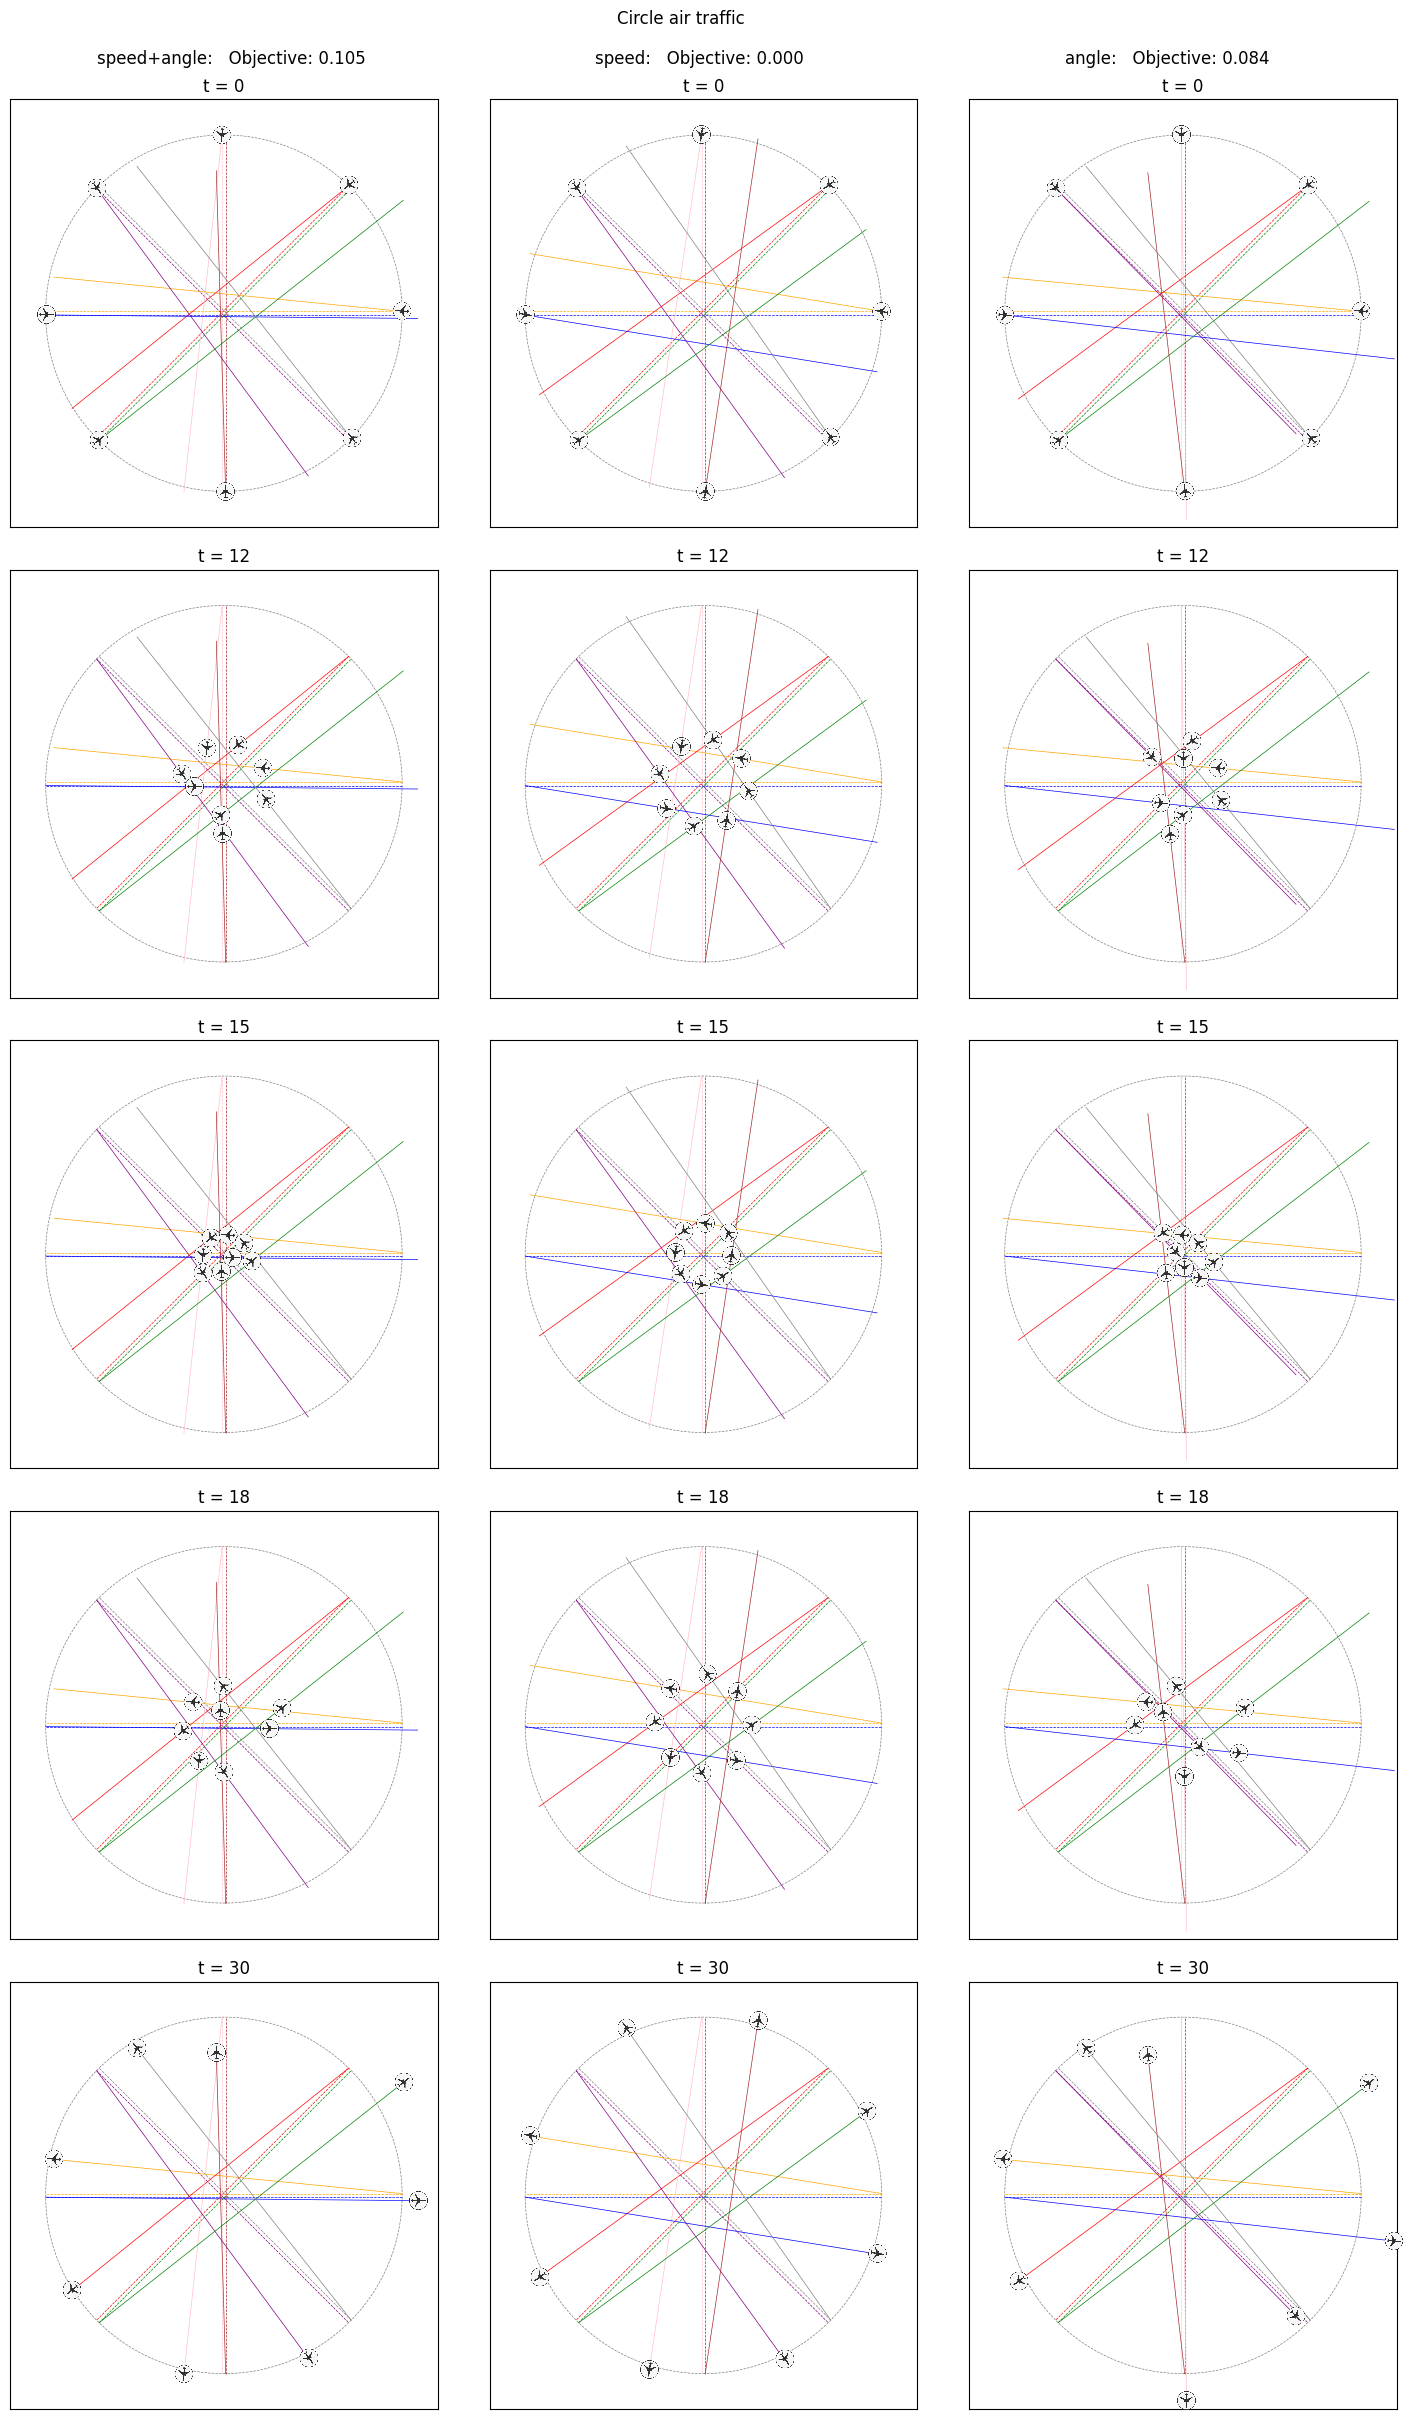

In [27]:
if anim:
    display(
        animate_air_traffic_comparison(
            air_traffic_0, [model_0, model_0_bis, model_0_ter]
        )
    )
else:
    show_time_compar_0 = [0, 12, 15, 18, 30]
    show_output_comparison(
        air_traffic_0, [model_0, model_0_bis, model_0_ter], show_time_compar_0, show_circle=True
    )

From left to right, the initial objective, the minimization of speed, and the minimization of angle. 

We can see that if we only minimize the speeds, the aircraft take the maximum possible heading angle, without changing the speeds (objective function of 0 here), and the new arrangement is now symmetrical.
If we minimize only the heading angles, the plane will increase its speed and further reduce its deviation angle.

Here is the comparison on another example.

In [28]:
model_2_bis = create_model(air_traffic_2, "speed")
result = solver.solve(model_2_bis, tee=True)

Artelys Knitro 15.0.0: mip_multistart=1
mip_maxnodes=500

          Commercial License
         Artelys Knitro 15.0.0

No start point provided -- Knitro computing one.

concurrent_evals         0
datacheck                0
feastol                  1e-06
feastol_abs              1e-06
findiff_numthreads       1
hessian_no_f             1
hessopt                  1
mip_maxnodes             500
mip_multistart           1
opttol                   1e-06
opttol_abs               0.001
Knitro changing mip_method from AUTO to 1.
Knitro changing mip_root_nlpalg from AUTO to 1.
Knitro changing mip_branchrule from AUTO to 2.
Knitro changing mip_selectrule from AUTO to 2.
Knitro changing mip_mir from AUTO to 2.
Knitro changing mip_clique from AUTO to 0.
Knitro changing mip_zerohalf from AUTO to 0.
Knitro changing mip_liftproject from AUTO to 0.
Knitro changing mip_knapsack from AUTO to 2.
Knitro changing mip_gomory from AUTO to 0.
Knitro changing mip_cut_flowcover from AUTO to 2.
Knitro changing m

In [29]:
model_2_ter = create_model(air_traffic_2, "angle")
result = solver.solve(model_2_ter, tee=True)

Artelys Knitro 15.0.0: mip_multistart=1
mip_maxnodes=500

          Commercial License
         Artelys Knitro 15.0.0

No start point provided -- Knitro computing one.

concurrent_evals         0
datacheck                0
feastol                  1e-06
feastol_abs              1e-06
findiff_numthreads       1
hessian_no_f             1
hessopt                  1
mip_maxnodes             500
mip_multistart           1
opttol                   1e-06
opttol_abs               0.001
Knitro changing mip_method from AUTO to 1.
Knitro changing mip_root_nlpalg from AUTO to 1.
Knitro changing mip_branchrule from AUTO to 2.
Knitro changing mip_selectrule from AUTO to 2.
Knitro changing mip_mir from AUTO to 2.
Knitro changing mip_clique from AUTO to 0.
Knitro changing mip_zerohalf from AUTO to 0.
Knitro changing mip_liftproject from AUTO to 0.
Knitro changing mip_knapsack from AUTO to 2.
Knitro changing mip_gomory from AUTO to 0.
Knitro changing mip_cut_flowcover from AUTO to 2.
Knitro changing m

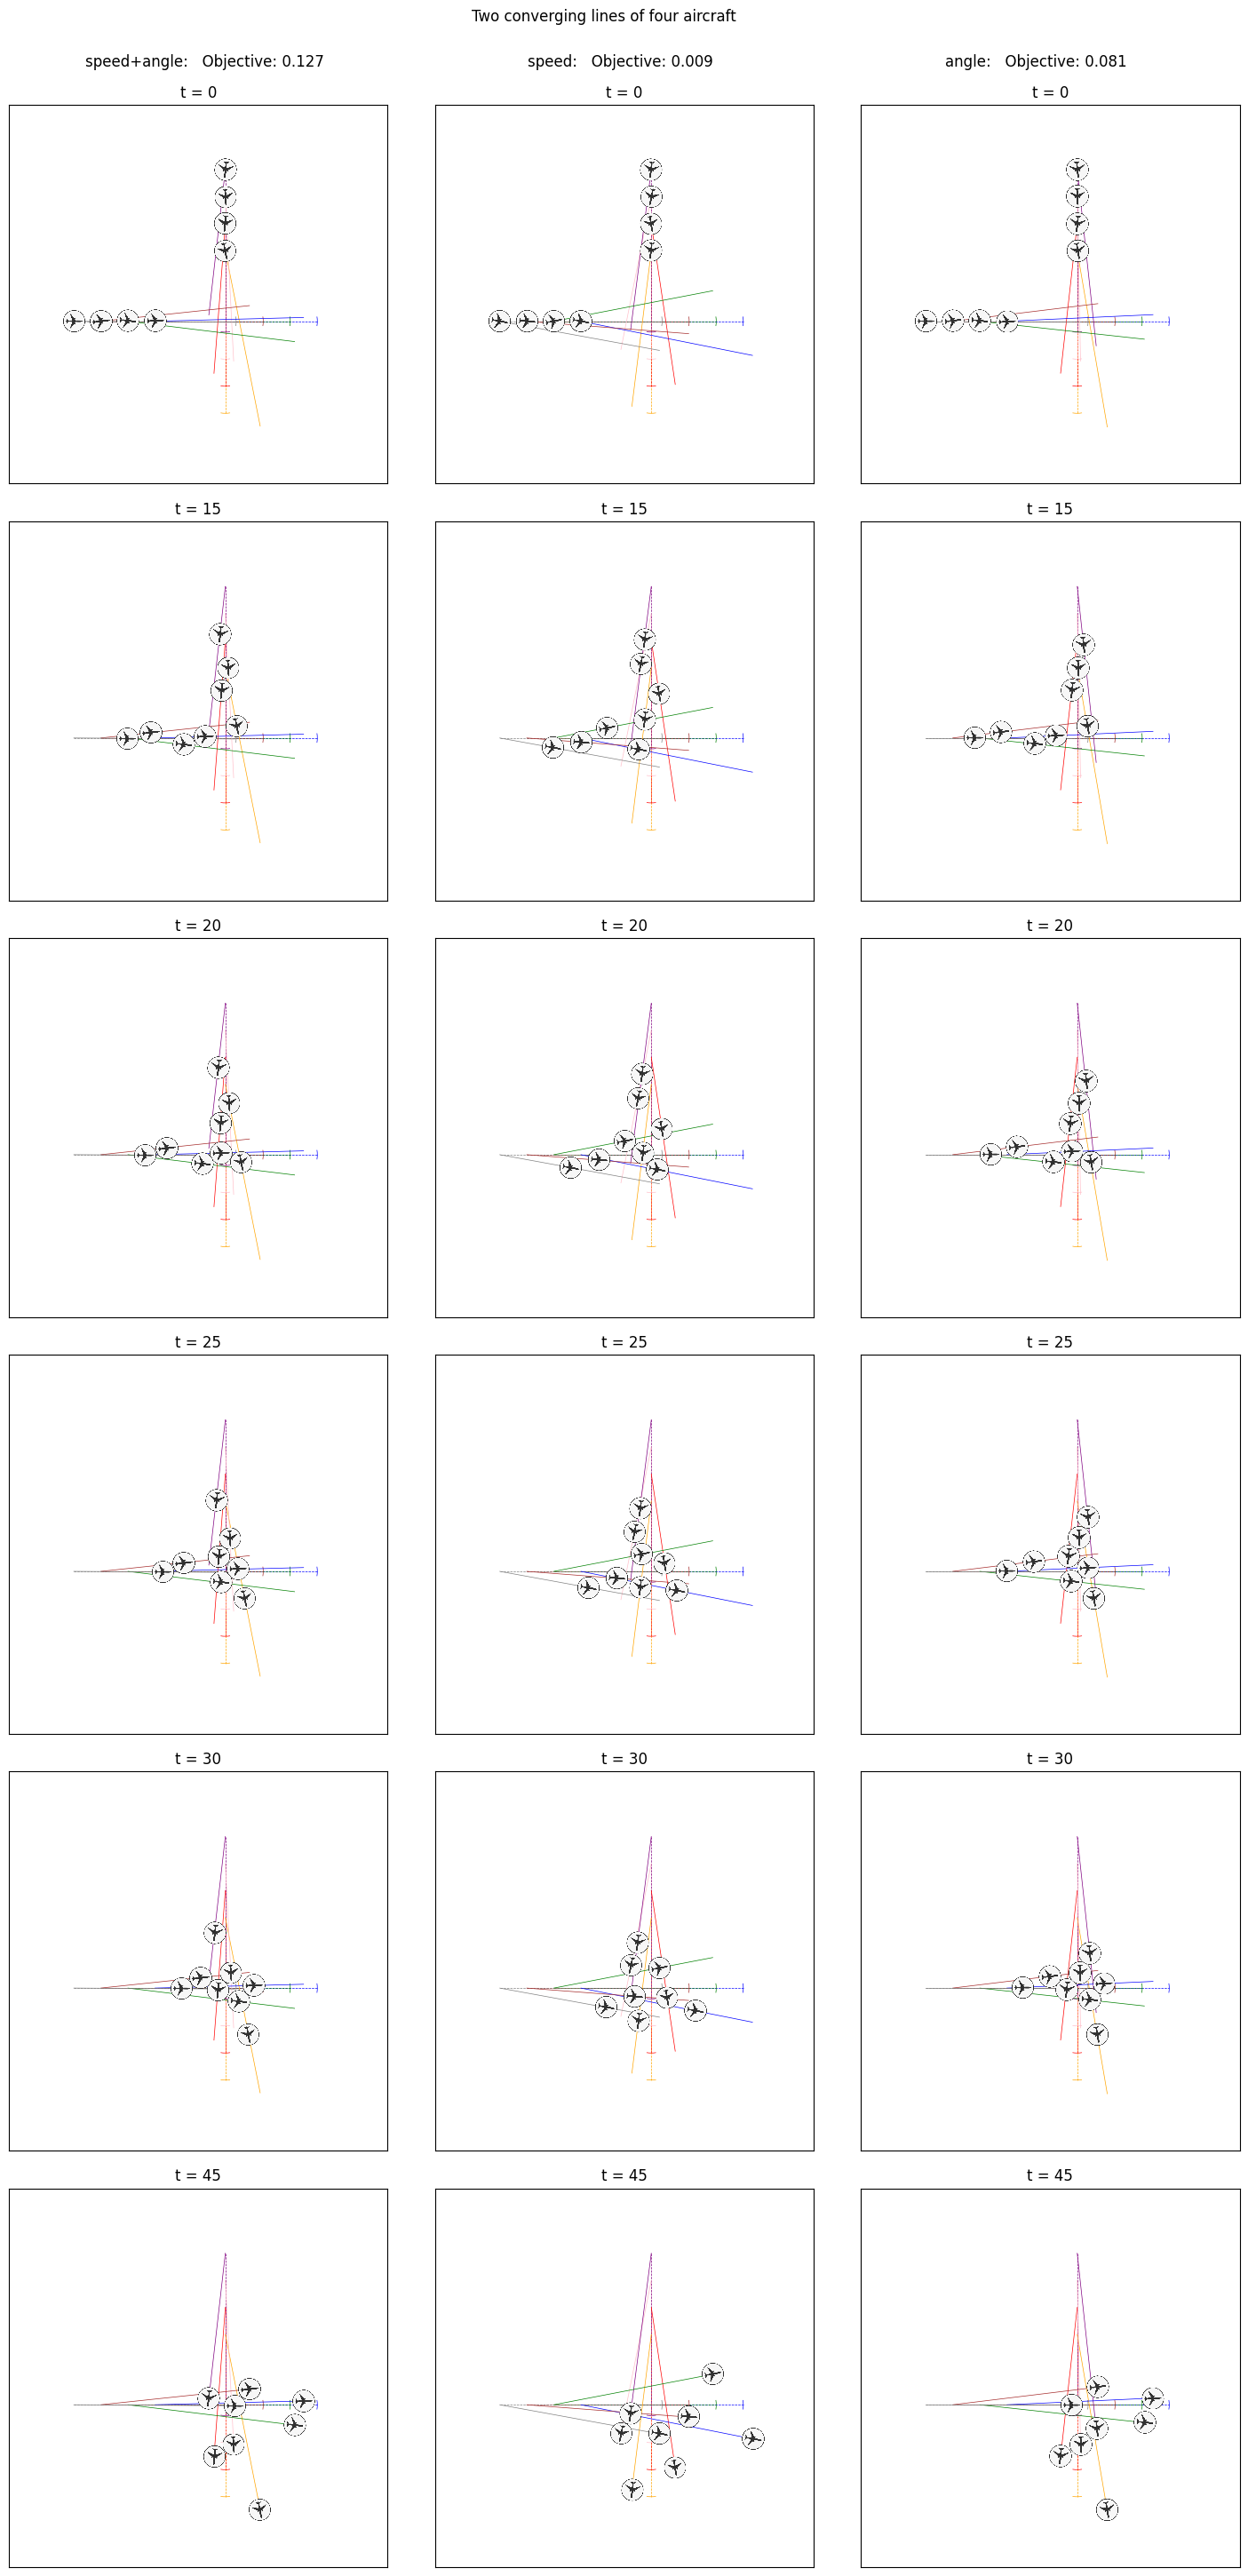

In [30]:
if anim:
    display(
        animate_air_traffic_comparison(
            air_traffic_2, [model_2, model_2_bis, model_2_ter]
        )
    )
else:
    show_time_compar_1 = [0, 15, 20, 25, 30, 45]
    show_output_comparison(
        air_traffic_2, [model_2, model_2_bis, model_2_ter], show_time_compar_1,show_arc_limits=True
    )

We do not see in this example a significant change in the flight paths, but we still observe that, depending on what we minimize, the results are different, and the aircraft do not cross the opposite row in the same order.

## References

* "Aircraft deconfliction via Mathematical Programming: Review and insights" - Mercedes Pelegrín, Claudia d’Ambrosio (2020)
* "Resolution of Conflicts Involving Many Aircraft via Semidefinite Programming" - E. Frazzoli, Z.-H. Mao, J.-H. Oh, E. Feron (1999)